In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from scipy import stats
import tensorflow as tf
import seaborn as sns
from pylab import rcParams
from sklearn.model_selection import train_test_split
from keras.models import Model, load_model
from keras.layers import Input, Dense
from keras.callbacks import ModelCheckpoint, TensorBoard
from keras import regularizers

%matplotlib inline

sns.set(style='whitegrid', palette='muted', font_scale=1.5)



In [3]:
trainfile = "C:\\Users\\LOUAY\\OneDrive\\Bureau\\pwc stage 4 eme fraud\\fraudTest\\fraudTrain.csv"
testfile = "C:\\Users\\LOUAY\\OneDrive\\Bureau\\pwc stage 4 eme fraud\\fraudTest\\fraudTest.csv"

In [4]:
train_data = pd.read_csv(trainfile)
test_data = pd.read_csv(testfile)

# Exploration

In [5]:
train_data.shape

(1296675, 23)

In [6]:
train_data.isnull().values.any()

False

In [7]:
# Count zeros in each column
zero_counts = (train_data == 0).sum()

# Display the results
print("Number of zeros in each column:")
print(zero_counts)


Number of zeros in each column:
Unnamed: 0                     1
trans_date_trans_time          0
cc_num                         0
merchant                       0
category                       0
amt                            0
first                          0
last                           0
gender                         0
street                         0
city                           0
state                          0
zip                            0
lat                            0
long                           0
city_pop                       0
job                            0
dob                            0
trans_num                      0
unix_time                      0
merch_lat                      0
merch_long                     0
is_fraud                 1289169
dtype: int64


In [60]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Columns: 803 entries, trans_date_trans_time to std_trans_amt
dtypes: datetime64[ns](2), float64(10), int32(1), int64(14), object(6), uint8(770)
memory usage: 1.2+ GB


# Explanation of Each Column

trans_date_trans_time: The date and time when the transaction occurred.

cc_num: The credit card number.

merchant: The merchant where the transaction took place.

category: The category of the transaction (e.g., shopping, food, etc.).

amt: The amount of the transaction.

first: The first name of the credit card holder.

last: The last name of the credit card holder.

gender: The gender of the credit card holder.

street: The street address of the credit card holder.

city: The city of the credit card holder.

state: The state of the credit card holder.

zip: The zip code of the credit card holder.

lat: The latitude of the credit card holder's location.

long: The longitude of the credit card holder's location.

city_pop: The population of the city where the credit card holder resides.

job: The job title of the credit card holder.

dob: The date of birth of the credit card holder.

trans_num: The transaction number.

unix_time: The Unix timestamp of the transaction. Unix time 0 corresponds to 00:00:00 UTC on 1 January 1970.
Unix time 1609459200 corresponds to 00:00:00 UTC on 1 January 2021.

merch_lat: The latitude of the merchant's location.

merch_long: The longitude of the merchant's location.

is_fraud: A binary indicator of whether the transaction is fraudulent (1) or not (0).

In [9]:
train_data.describe()

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


In [10]:
train_data.nunique()

Unnamed: 0               1296675
trans_date_trans_time    1274791
cc_num                       983
merchant                     693
category                      14
amt                        52928
first                        352
last                         481
gender                         2
street                       983
city                         894
state                         51
zip                          970
lat                          968
long                         969
city_pop                     879
job                          494
dob                          968
trans_num                1296675
unix_time                1274823
merch_lat                1247805
merch_long               1275745
is_fraud                       2
dtype: int64

In [11]:
# Remove the 'Unnamed: 0' column if it's just an index
train_data.drop(columns=['Unnamed: 0'], inplace=True)

In [12]:
# Statistical summary of numerical data
print(train_data.describe())

             cc_num           amt           zip           lat          long  \
count  1.296675e+06  1.296675e+06  1.296675e+06  1.296675e+06  1.296675e+06   
mean   4.171920e+17  7.035104e+01  4.880067e+04  3.853762e+01 -9.022634e+01   
std    1.308806e+18  1.603160e+02  2.689322e+04  5.075808e+00  1.375908e+01   
min    6.041621e+10  1.000000e+00  1.257000e+03  2.002710e+01 -1.656723e+02   
25%    1.800429e+14  9.650000e+00  2.623700e+04  3.462050e+01 -9.679800e+01   
50%    3.521417e+15  4.752000e+01  4.817400e+04  3.935430e+01 -8.747690e+01   
75%    4.642255e+15  8.314000e+01  7.204200e+04  4.194040e+01 -8.015800e+01   
max    4.992346e+18  2.894890e+04  9.978300e+04  6.669330e+01 -6.795030e+01   

           city_pop     unix_time     merch_lat    merch_long      is_fraud  
count  1.296675e+06  1.296675e+06  1.296675e+06  1.296675e+06  1.296675e+06  
mean   8.882444e+04  1.349244e+09  3.853734e+01 -9.022646e+01  5.788652e-03  
std    3.019564e+05  1.284128e+07  5.109788e+00  1.377

In [13]:
# Display frequency counts for categorical columns
for col in train_data.select_dtypes(include=['object']):
    print(train_data[col].value_counts())


2019-04-22 16:02:01    4
2020-06-01 01:37:47    4
2020-06-02 12:47:07    4
2019-11-18 23:03:49    3
2019-12-01 14:11:58    3
                      ..
2019-07-13 18:38:18    1
2019-07-13 18:37:26    1
2019-07-13 18:35:46    1
2019-07-13 18:35:41    1
2020-06-21 12:13:37    1
Name: trans_date_trans_time, Length: 1274791, dtype: int64
fraud_Kilback LLC                       4403
fraud_Cormier LLC                       3649
fraud_Schumm PLC                        3634
fraud_Kuhn LLC                          3510
fraud_Boyer PLC                         3493
                                        ... 
fraud_Douglas, DuBuque and McKenzie      775
fraud_Treutel-King                       775
fraud_Medhurst, Labadie and Gottlieb     759
fraud_Reichert-Weissnat                  753
fraud_Hahn, Douglas and Schowalter       727
Name: merchant, Length: 693, dtype: int64
gas_transport     131659
grocery_pos       123638
home              123115
shopping_pos      116672
kids_pets         113035
shop

# Initial Observations 
Entries: The dataset contains 1,296,675 entries.
Columns: There are 23 columns, including a mix of numerical, categorical, and temporal data.
Data types: There are various data types, including object (likely strings in pandas), integers, and floats.


# Potential Data Cleaning Steps

-Trans_date_trans_time: Convert this from object (string) to datetime to facilitate time series analysis and feature extraction related to dates and times.

-DOB: This should also be converted from object to datetime to analyze customer demographics more effectively.

-Categorical Data Conversion: Columns like merchant, category, gender, street, city, state, job, and trans_num are currently in string format. For some analyses, it may be useful to convert these to categorical codes.

-Geographical Data: The dataset includes geographic coordinates (latitude and longitude for both customer and merchant). This data can be used to explore geographical patterns in transactions and fraud occurrences.

-No missing data: All columns have 1,296,675 non-null entries, which indicates there are no missing values in your dataset.

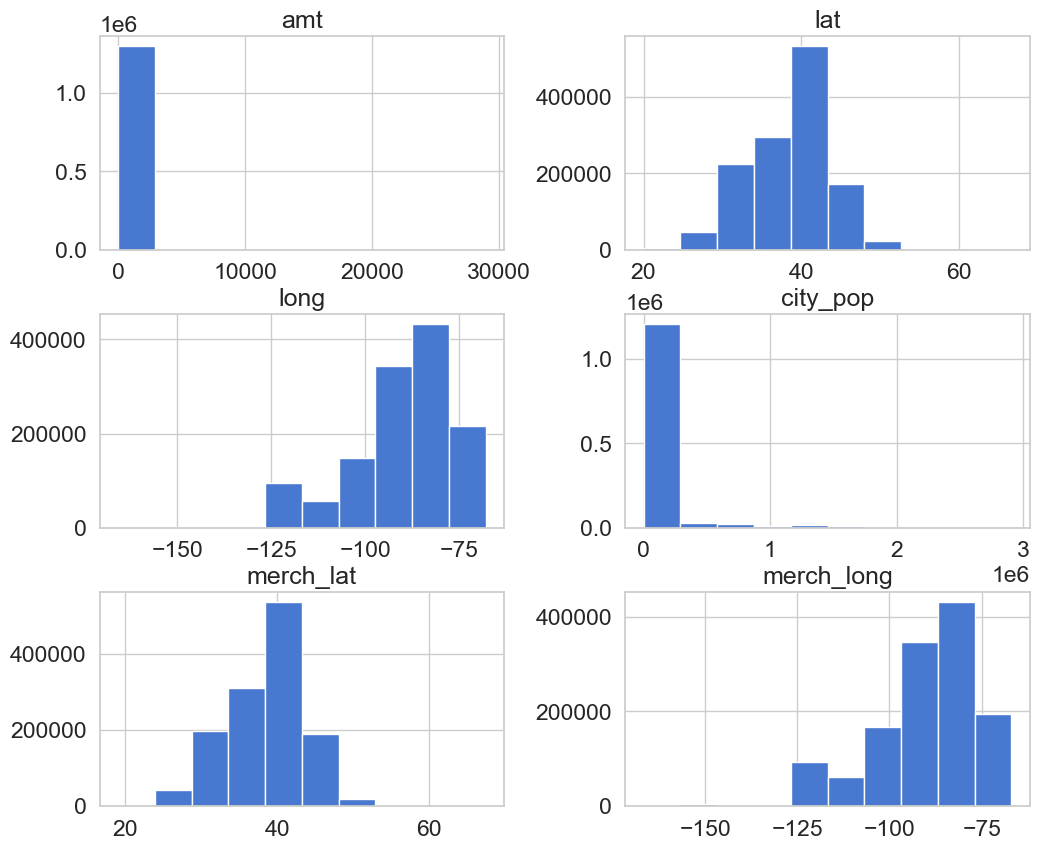

In [14]:
# Histogram of numerical features
num_features = ['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long']
train_data[num_features].hist(figsize=(12, 10))
plt.show()

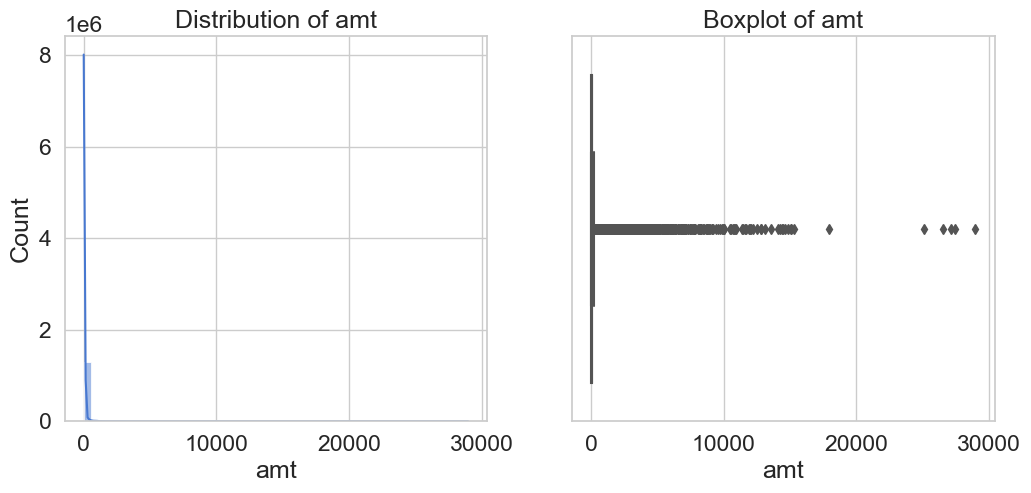

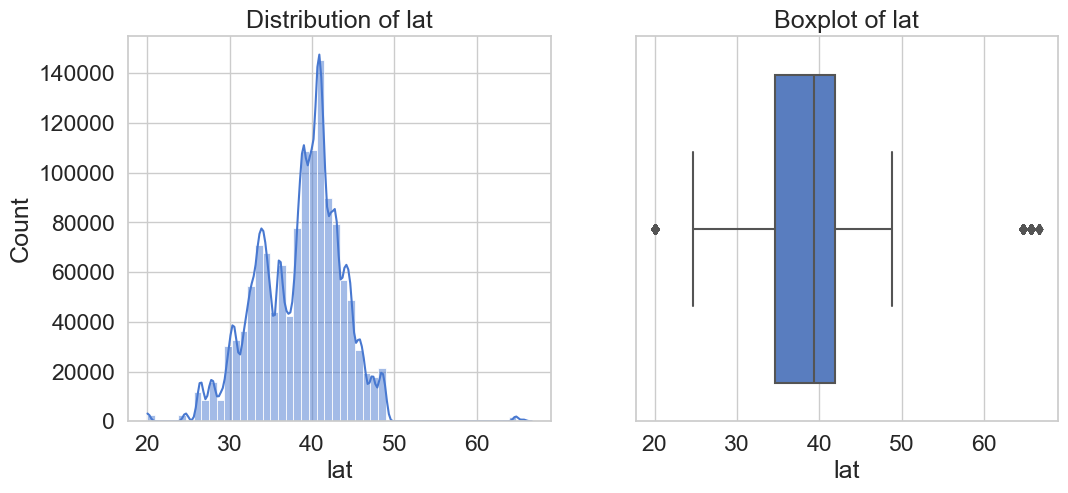

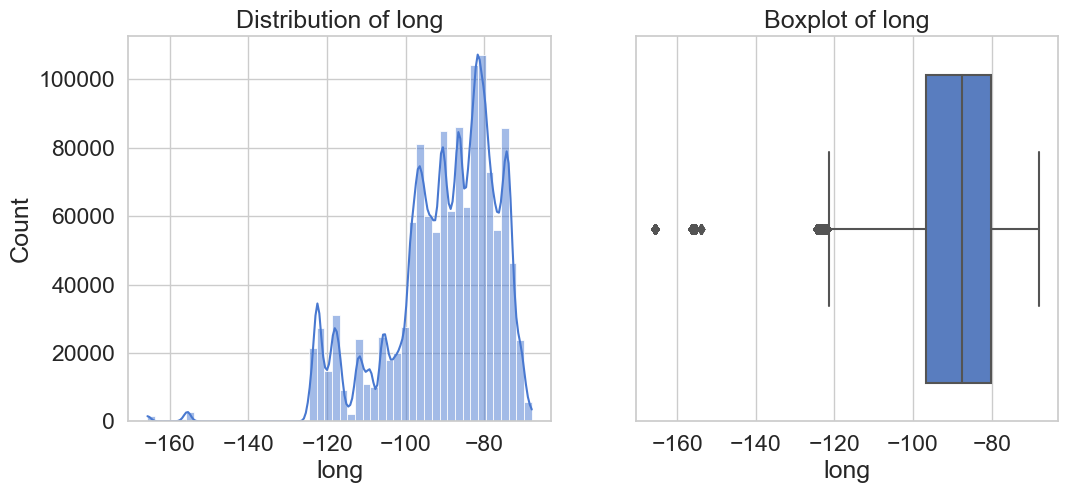

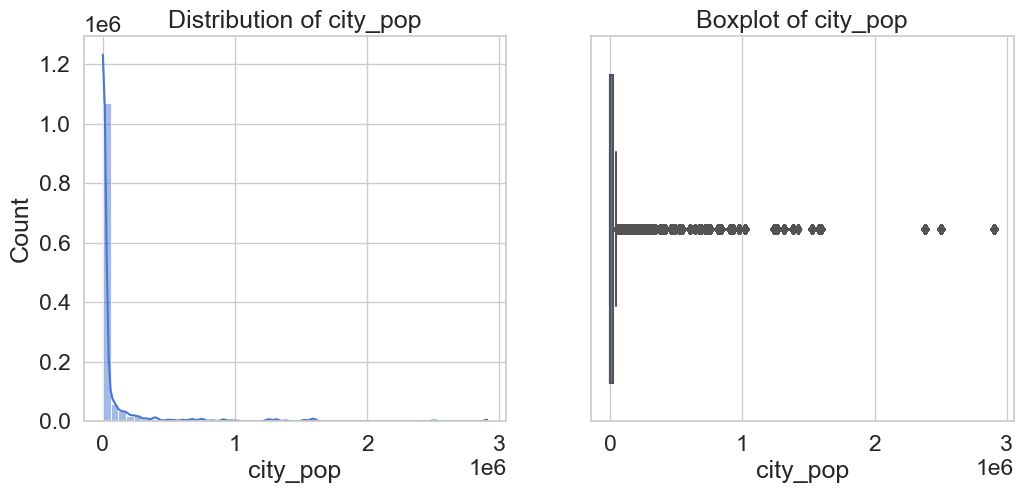

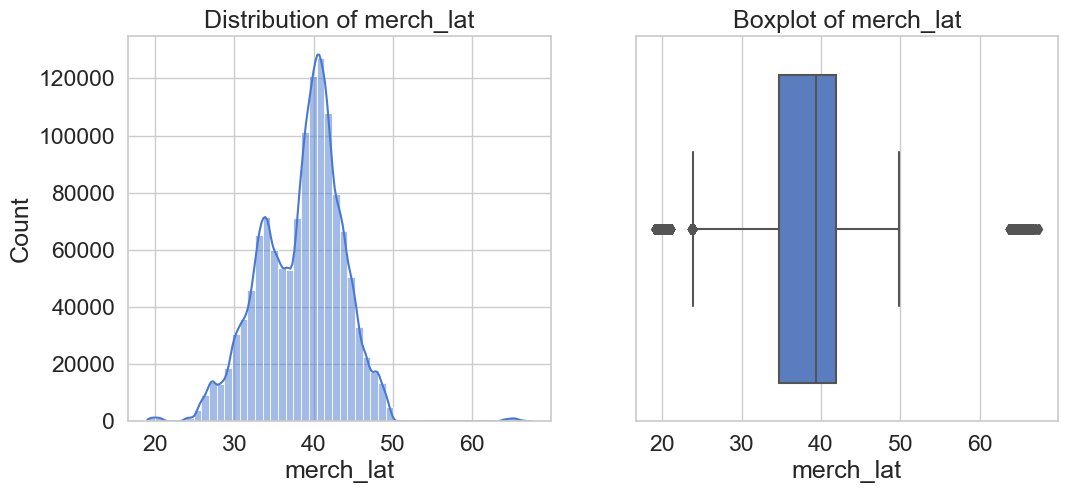

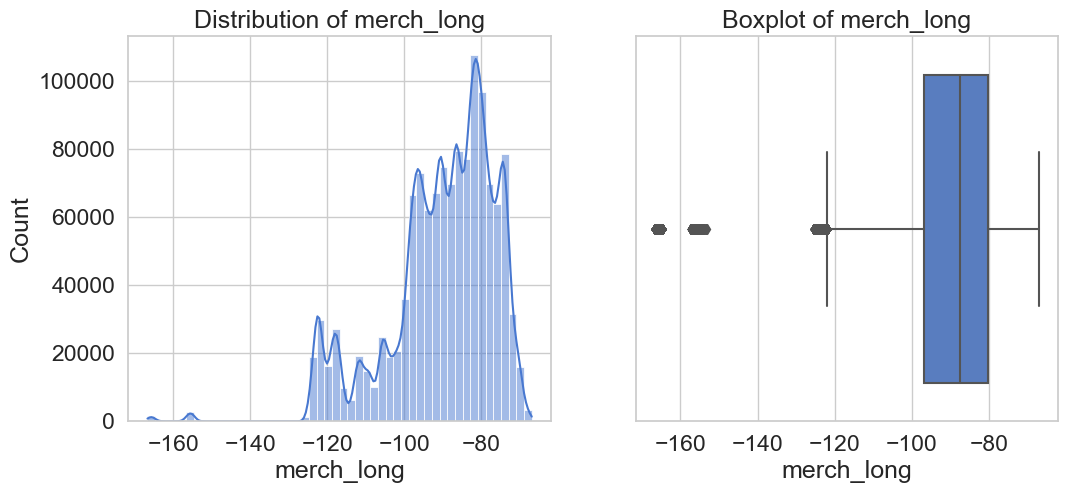

In [15]:
# Import necessary libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Numerical Features
num_features = ['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long']

# Plot histograms and box plots
for feature in num_features:
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    sns.histplot(train_data[feature], bins=50, kde=True)
    plt.title(f'Distribution of {feature}')
    
    plt.subplot(1, 2, 2)
    sns.boxplot(x=train_data[feature])
    plt.title(f'Boxplot of {feature}')
    plt.show()


# Histogram
-amt:

The majority of transaction amounts are concentrated at the lower end, with a significant number of transactions below $5000.
There are some high-value transactions, but they are much less frequent.

-lat and long:

The latitude (lat) values mostly range from 25 to 50 .
The longitude (long) values show a wider distribution, predominantly between -120 and -80 degrees.

-city_pop:

Most of the city populations are heavily skewed towards smaller values, with a significant number of cities having a population close to zero.
There are very few cities with larger populations.

-merch_lat and merch_long:

The latitude (merch_lat) and longitude (merch_long) of merchants show similar distributions to the cardholders’ latitude and longitude , mech_lat range from 25 to 50, merch_long range from -120 to -80

# Univariate Analysis

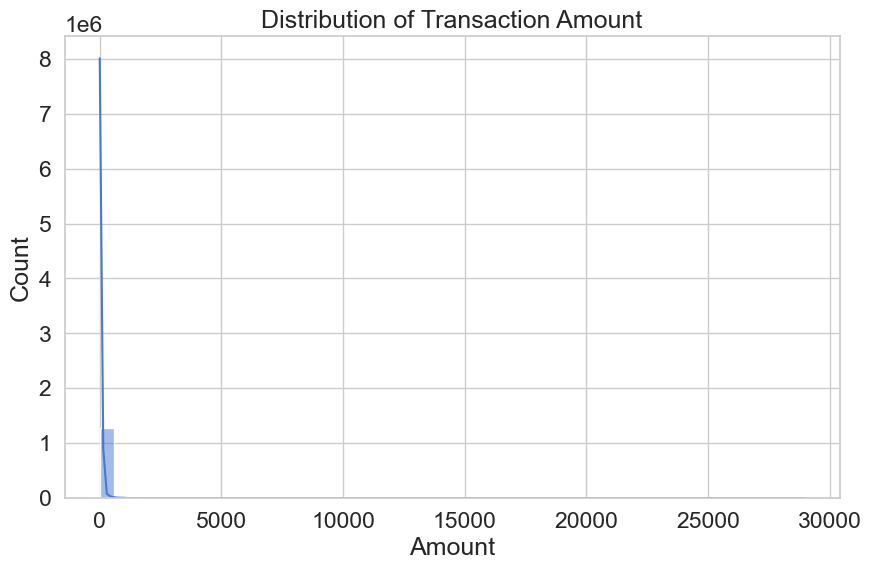

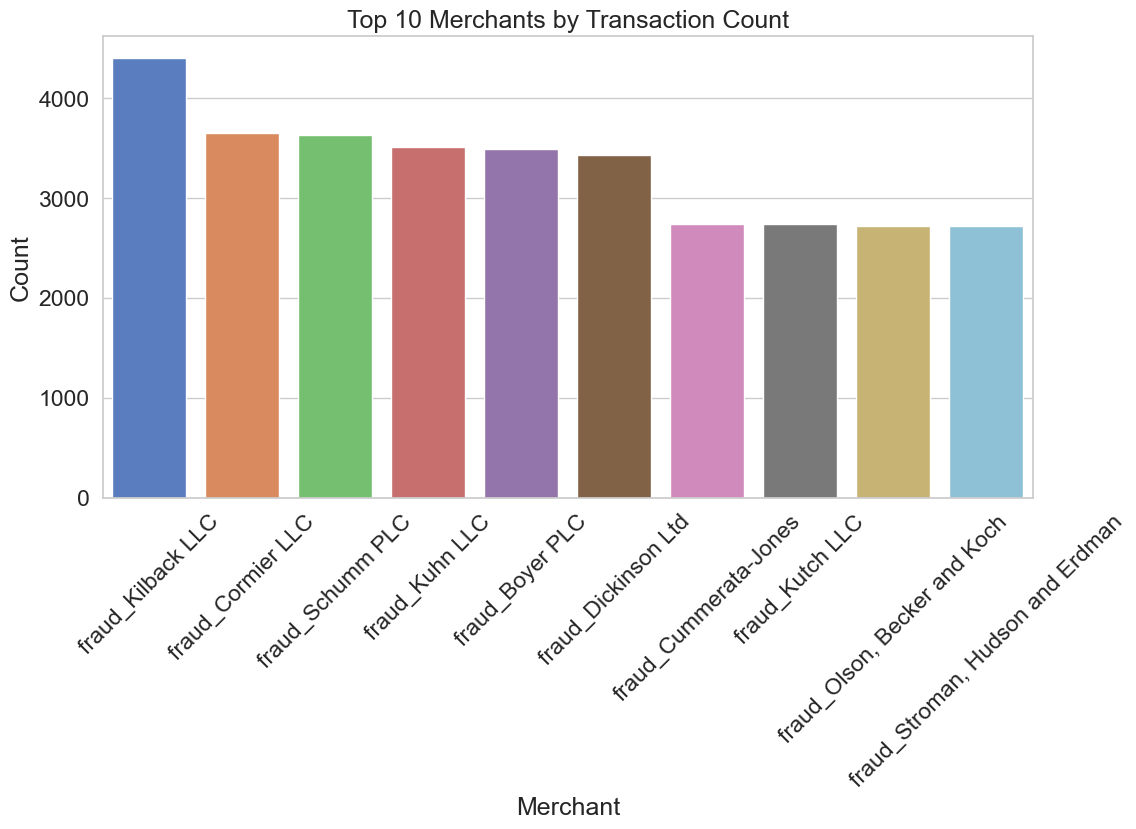

In [16]:
# Example for numeric variables (e.g., 'amt')
plt.figure(figsize=(10, 6))
sns.histplot(train_data['amt'], bins=50, kde=True)
plt.title('Distribution of Transaction Amount')
plt.xlabel('Amount')
plt.ylabel('Count')
plt.show()

# Example for categorical variables (e.g., 'merchant')
plt.figure(figsize=(12, 6))
sns.countplot(x='merchant', data=train_data, order=train_data['merchant'].value_counts().index[:10])
plt.title('Top 10 Merchants by Transaction Count')
plt.xticks(rotation=45)
plt.xlabel('Merchant')
plt.ylabel('Count')
plt.show()


# Observations:
The histogram shows that the majority of transaction amounts are low, close to the y-axis.
The tail on the right indicates the presence of some high-value transactions, which are outliers.
Transactions with high amounts (in the right tail) might be potential indicators of fraud.
These high-value transactions should be investigated further to understand their nature.

The top merchant by transaction count is 'fraud_Kilback LLC,' followed by 'fraud_Cormier LLC,' and 'fraud_Schumm PLC.'
The counts for the top merchants are relatively close, with the highest around 4,000 transactions.


# Bivariate Analysis

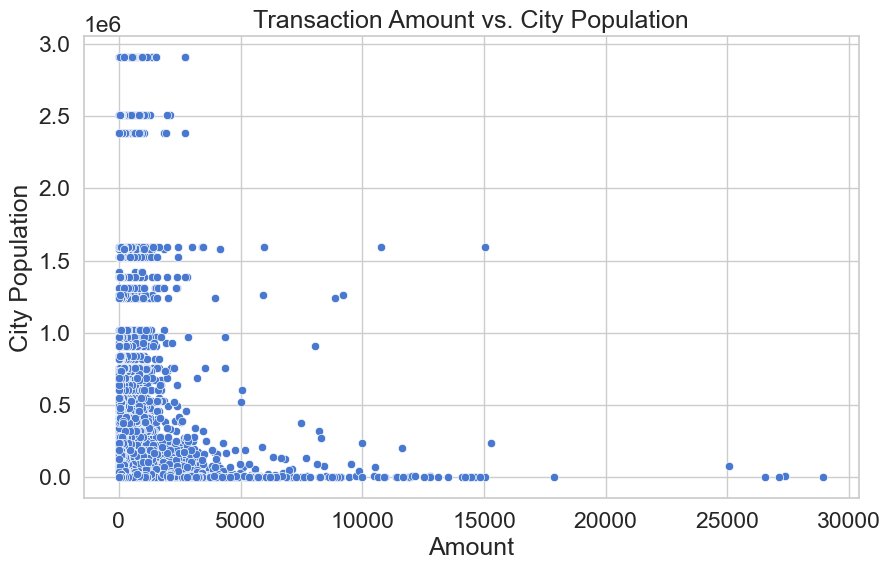

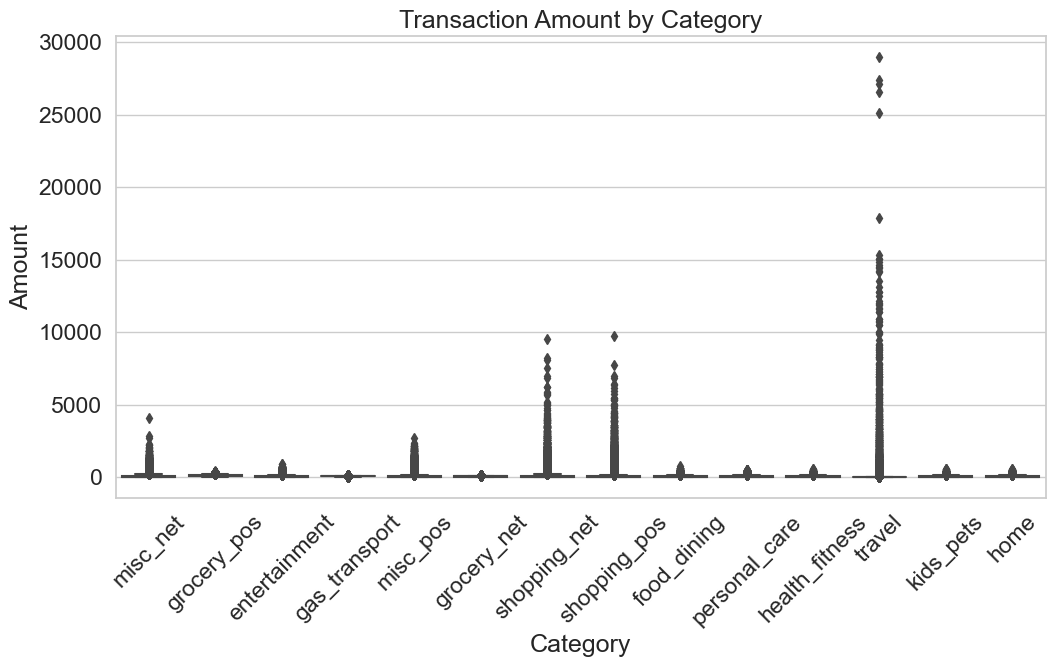

In [17]:
# Example for numeric vs. numeric (e.g., 'amt' vs. 'city_pop')
plt.figure(figsize=(10, 6))
sns.scatterplot(x='amt', y='city_pop', data=train_data)
plt.title('Transaction Amount vs. City Population')
plt.xlabel('Amount')
plt.ylabel('City Population')
plt.show()

# Example for categorical vs. numeric (e.g., 'category' vs. 'amt')
plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='amt', data=train_data)
plt.title('Transaction Amount by Category')
plt.xticks(rotation=45)
plt.xlabel('Category')
plt.ylabel('Amount')
plt.show()


# Analysis of Transaction Amount vs. City Population

Transaction Amount Distribution:

Most transactions are clustered around lower amounts.

There are fewer high-value transactions, and these are spread across different city populations.

City Population Distribution:

Transactions occur in cities with a wide range of populations.

Higher transaction amounts are distributed across both low and high population cities.

Sparse High-Value Transactions:

High-value transactions (> $10,000) are rare and scattered across various city populations.


Fraud Detection:

High-value transactions in low-population cities might be unusual and worth investigating for potential fraud.

Analyzing the density of transactions across city populations can help identify anomalies.

Insights:

Understanding transaction distributions across city populations can assist in targeting marketing efforts and resource allocation.


# Analysis of Transaction Amount by Category

Category Distribution:

The majority of transaction amounts are clustered at lower values across all categories.

Notable Outliers:

Categories like "shopping_net","shopping_pos" and "travel" have significantly higher transaction amounts, with some outliers reaching up to $30,000.

Concentration of Transactions:

Most categories have a tight cluster of low-value transactions.

"Travel" and "shopping_net" show a broader range of transaction amounts, including several high-value transactions.

Fraud Detection:

Categories with high-value outliers, such as "travel" and "shopping_net," may need closer verifications for fraudulent activities.

Insights:

Categories with higher transaction amounts, such as "travel," indicate high-value spending, which might be typical for these categories.


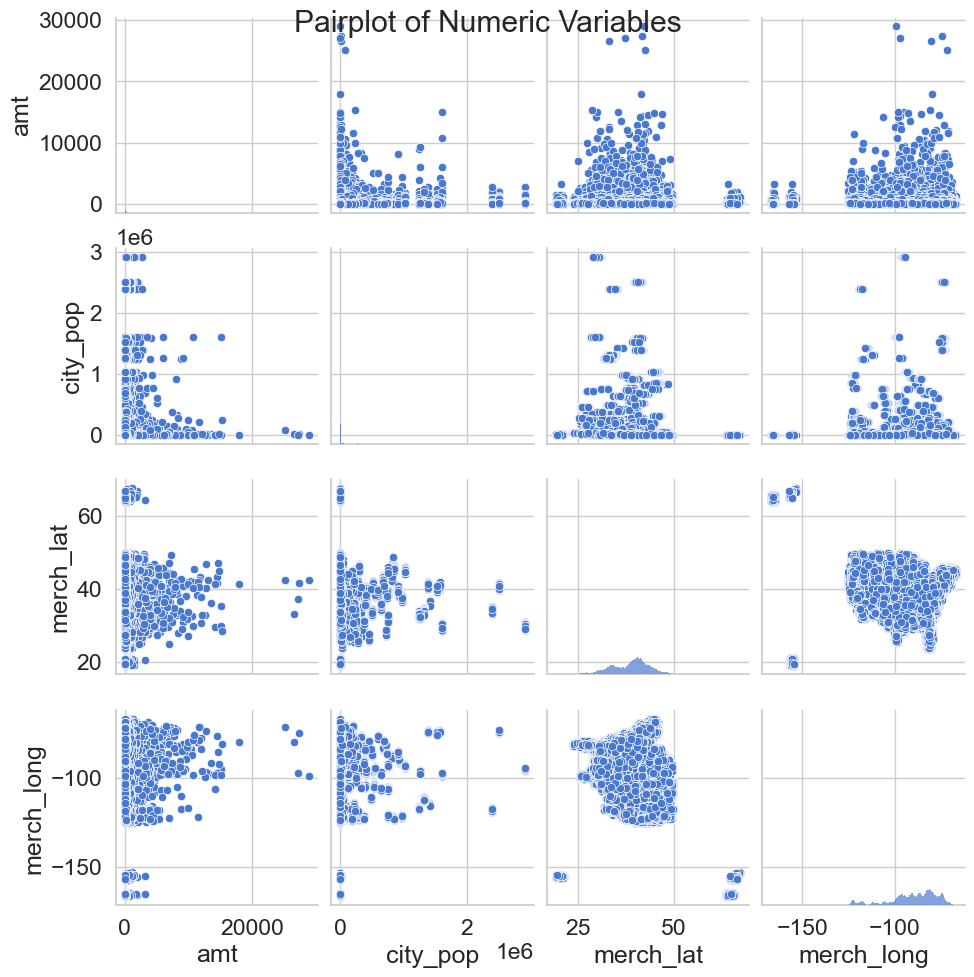

In [18]:
sns.pairplot(train_data[['amt', 'city_pop', 'merch_lat', 'merch_long']])
plt.suptitle('Pairplot of Numeric Variables')
plt.show()


# Observations

Transaction Amount (amt):

The scatter plots involving amt show a heavy concentration of low-value transactions.

There are few high-value transactions spread out across different city_pop, merch_lat, and merch_long.

City Population (city_pop):

Transactions are more densely clustered at lower city populations.

There are few instances of transactions in high-population cities.

Merchant Latitude (merch_lat) and Longitude (merch_long):

Transactions are distributed across a range of latitudes and longitudes.

The majority of transactions are within specific latitude and longitude ranges, with few outliers.

Relationships Between Variables:

There is no obvious linear relationship between amt and other variables, indicating the complexity of factors influencing transaction amounts.

The density plots on the diagonal indicate that most variables are not normally distributed and are skewed.

Fraud Detection:

The lack of strong linear relationships suggests that fraudulent activity might not be easily predicted by a single variable and may require a more complex model.

The presence of outliers in the amt variable across different city populations and geographic locations warrants further investigation.

Geographical Insights:

Transactions are widely distributed geographically, indicating that fraud detection models should account for geographic diversity.

Anomalies in merchant locations could also be indicative of fraudulent activity.

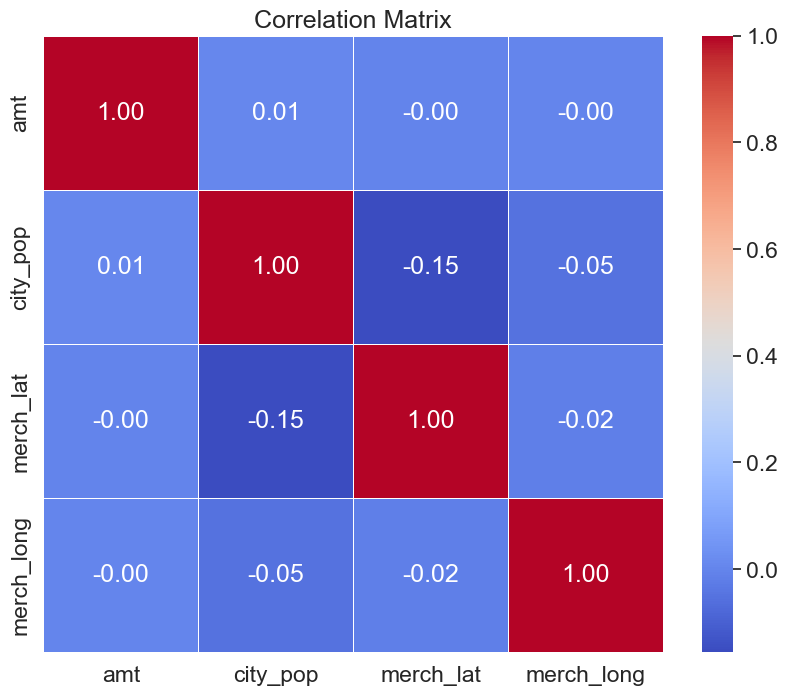

In [19]:
correlation_matrix = train_data[['amt', 'city_pop', 'merch_lat', 'merch_long']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix')
plt.show()


# Observations:
Transaction Amount (amt):

amt shows very weak correlations with all other variables (city_pop, merch_lat, and merch_long), with values close to 0.

City Population (city_pop):

city_pop also shows very weak correlations with merch_lat and merch_long.

Merchant Latitude (merch_lat) and Longitude (merch_long):

merch_lat and merch_long have a correlation value of 1.00 with themselves, as expected.

They show very weak correlations with other variables.

Implications:
Modeling Implications:

The weak correlations between amt and the other variables suggest that transaction amount alone does not directly depend on city population or merchant location.

This indicates that detecting fraud will likely require a more complex model that captures non-linear relationships and interactions between multiple variables.

Feature Engineering:

Additional features may need to be engineered to improve the model’s performance. For example, interactions between variables or domain-specific features that capture more complex patterns.

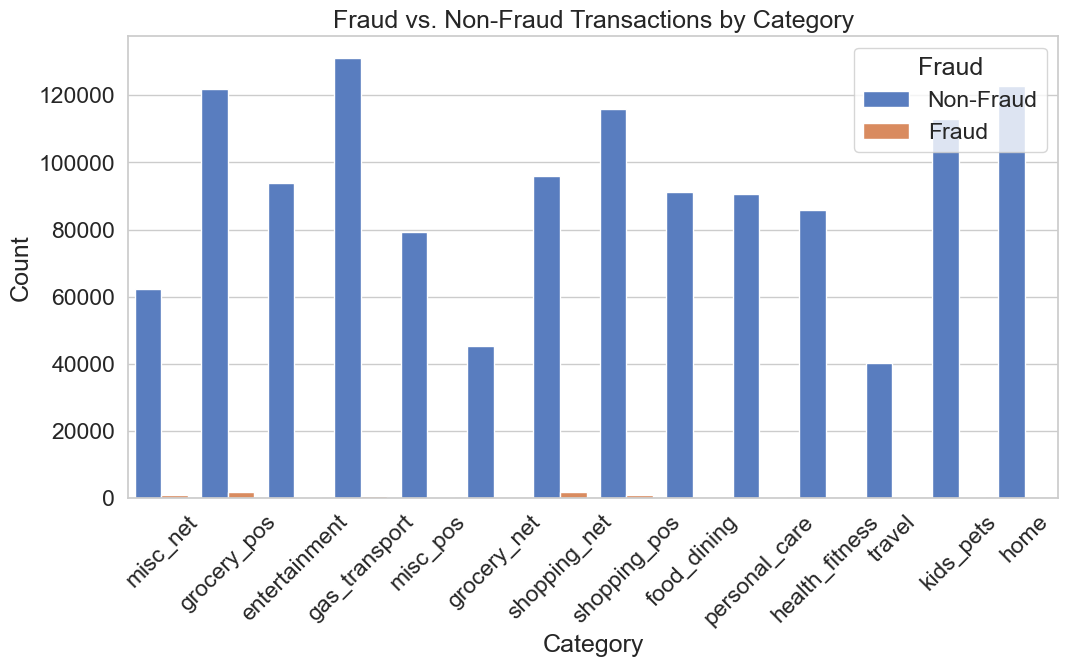

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming train_data is your DataFrame with 'category' and 'is_fraud' columns

# Create a new column with categorical labels for fraud status
train_data['fraud_label'] = train_data['is_fraud'].map({0: 'Non-Fraud', 1: 'Fraud'})

# Plotting
plt.figure(figsize=(12, 6))
sns.countplot(x='category', hue='fraud_label', data=train_data)
plt.title('Fraud vs. Non-Fraud Transactions by Category')
plt.xticks(rotation=45)
plt.xlabel('Category')
plt.ylabel('Count')
plt.legend(title='Fraud', loc='upper right')  # Adjust legend title if needed
plt.show()

# Remove the temporary column after plotting
train_data.drop('fraud_label', axis=1, inplace=True)


# Temporal Analysis

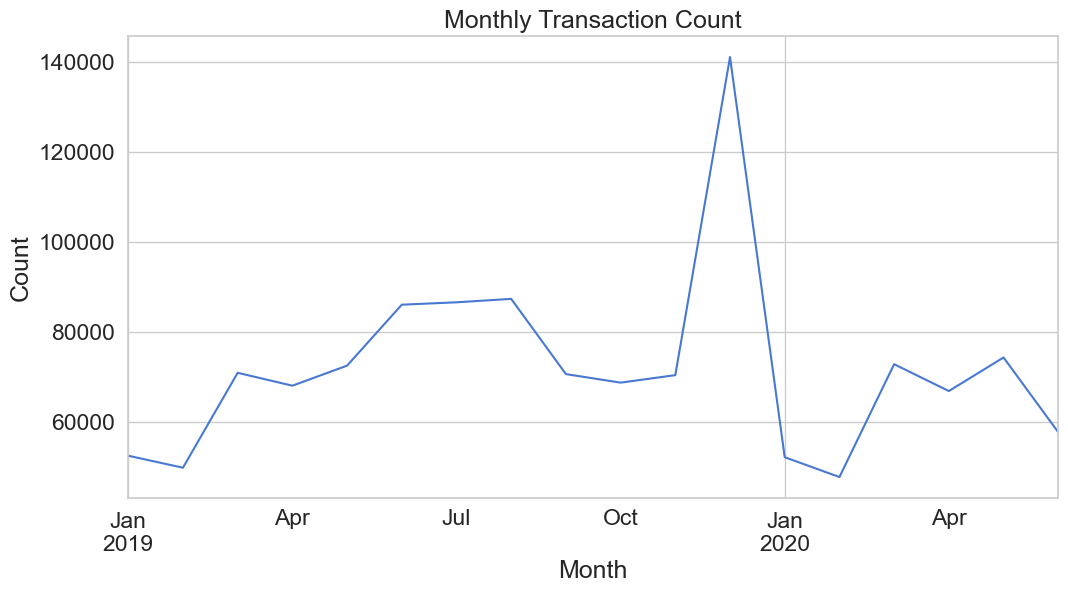

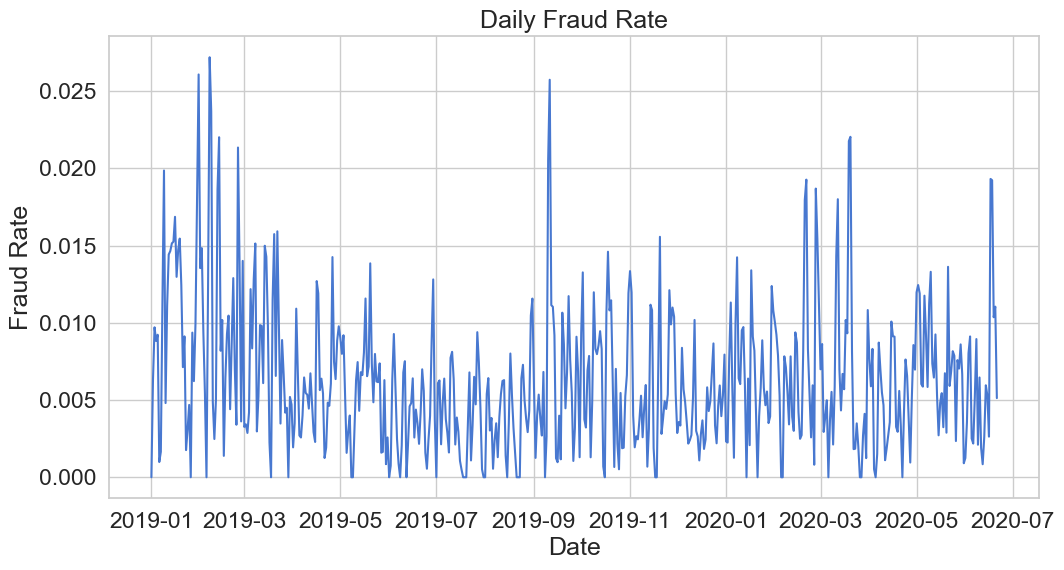

In [21]:
# Convert 'trans_date_trans_time' to datetime format
train_data['trans_date_trans_time'] = pd.to_datetime(train_data['trans_date_trans_time'])

# Example for monthly transaction count
monthly_counts = train_data.resample('M', on='trans_date_trans_time').size()

plt.figure(figsize=(12, 6))
monthly_counts.plot()
plt.title('Monthly Transaction Count')
plt.xlabel('Month')
plt.ylabel('Count')
plt.show()

# Example for fraud rate over time
train_data['date'] = train_data['trans_date_trans_time'].dt.date
fraud_rate = train_data.groupby('date')['is_fraud'].mean()

plt.figure(figsize=(12, 6))
fraud_rate.plot()
plt.title('Daily Fraud Rate')
plt.xlabel('Date')
plt.ylabel('Fraud Rate')
plt.show()


# Transaction Amount vs. Fraud Status

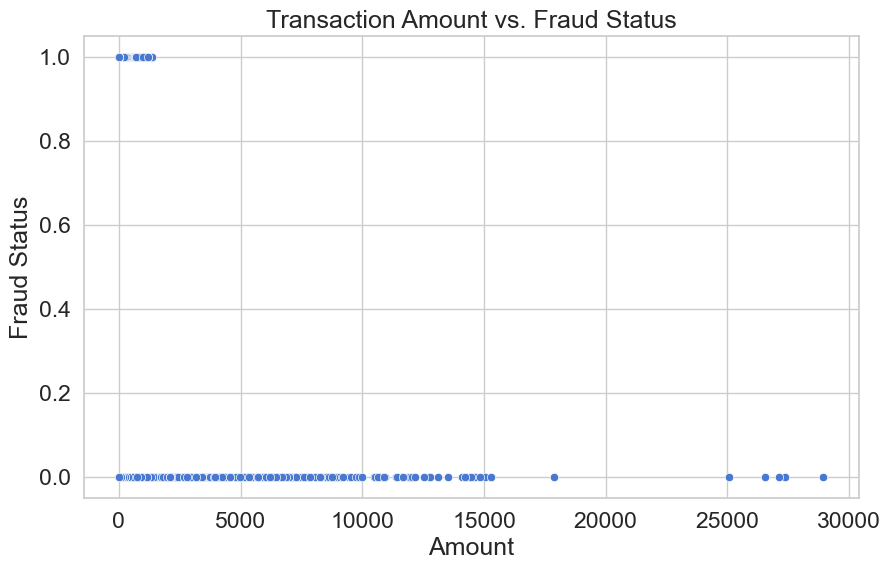

In [22]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='amt', y='is_fraud', data=train_data)
plt.title('Transaction Amount vs. Fraud Status')
plt.xlabel('Amount')
plt.ylabel('Fraud Status')
plt.show()


# Observations:
Distribution of Fraudulent Transactions:

Fraudulent transactions (Fraud Status = 1) appear across a range of transaction amounts but are densely clustered at lower amounts.

There are fewer fraudulent transactions at higher transaction amounts, although they do exist up to approximately $25,000.

Distribution of Non-Fraudulent Transactions:

Non-fraudulent transactions (Fraud Status = 0) are also concentrated at lower transaction amounts.

Similar to fraudulent transactions, non-fraudulent transactions are less frequent at higher amounts.

Comparison Between Fraudulent and Non-Fraudulent Transactions:

Both fraudulent and non-fraudulent transactions are primarily low-value, indicating that transaction amount alone may not be a strong indicator of fraud.


# Transaction Amount by Fraud Status

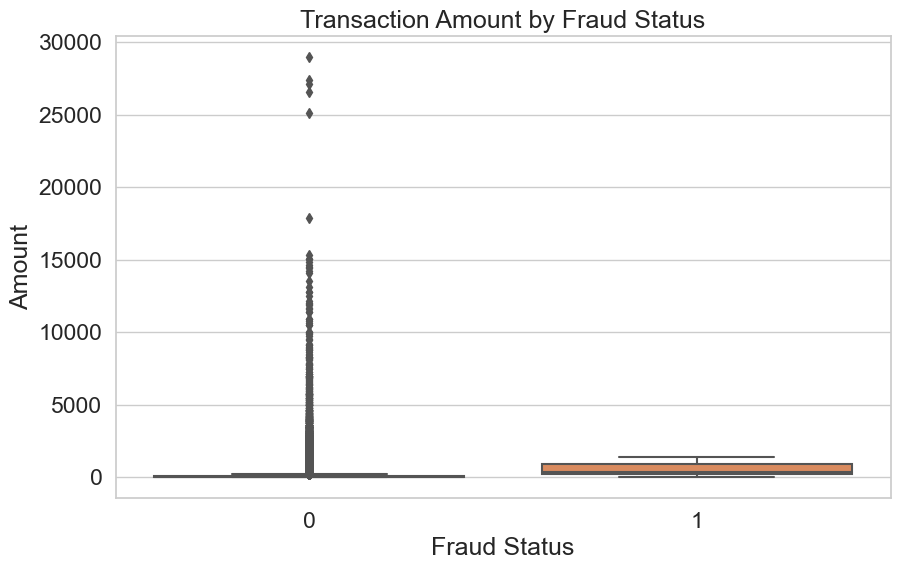

In [23]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='is_fraud', y='amt', data=train_data)
plt.title('Transaction Amount by Fraud Status')
plt.xlabel('Fraud Status')
plt.ylabel('Amount')
plt.show()


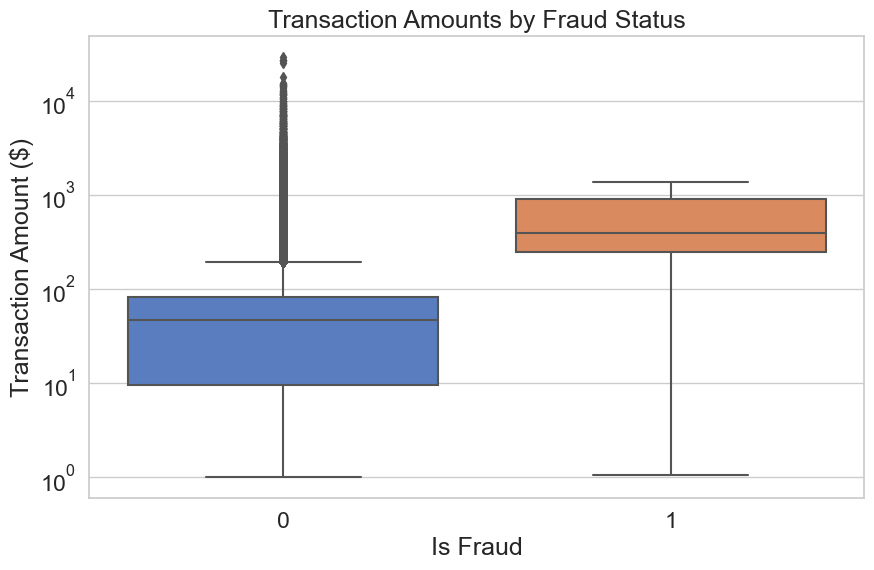

In [24]:
# Box plot of 'amt' by 'is_fraud'
plt.figure(figsize=(10, 6))
sns.boxplot(x='is_fraud', y='amt', data=train_data)
plt.yscale('log')
plt.title('Transaction Amounts by Fraud Status')
plt.xlabel('Is Fraud')
plt.ylabel('Transaction Amount ($)')
plt.show()


# Fraudulent vs Non-Fraudulent Analysis

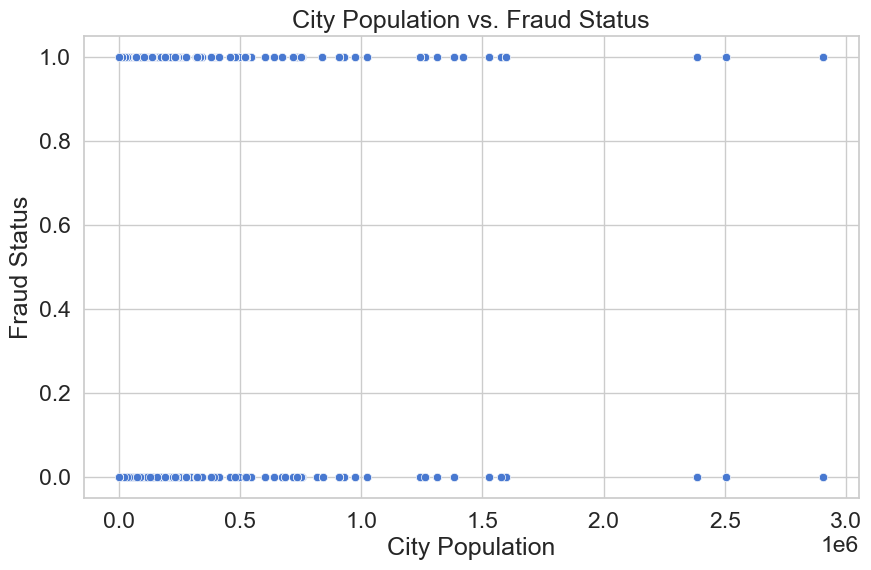

In [25]:
# Example for 'city_pop'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='city_pop', y='is_fraud', data=train_data)
plt.title('City Population vs. Fraud Status')
plt.xlabel('City Population')
plt.ylabel('Fraud Status')
plt.show()


# Distribution of fraud vs. non-fraud transactions (imbalanced)

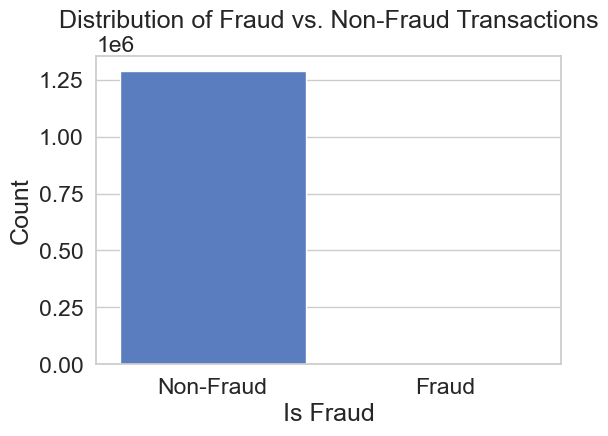

In [26]:

fraud_counts = train_data['is_fraud'].value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=fraud_counts.index, y=fraud_counts.values)
plt.title('Distribution of Fraud vs. Non-Fraud Transactions')
plt.xlabel('Is Fraud')
plt.ylabel('Count')
plt.xticks(ticks=fraud_counts.index, labels=['Non-Fraud', 'Fraud'])
plt.show()

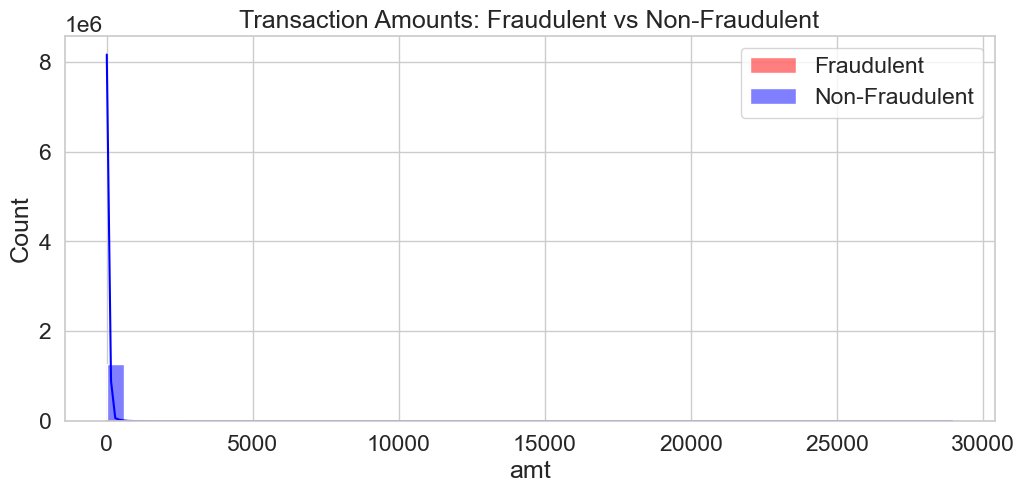

In [27]:
# Fraudulent vs Non-Fraudulent Analysis
fraud_data = train_data[train_data['is_fraud'] == 1]
non_fraud_data = train_data[train_data['is_fraud'] == 0]

# Compare the 'amt' distribution
plt.figure(figsize=(12, 5))
sns.histplot(fraud_data['amt'], bins=50, kde=True, color='red', label='Fraudulent')
sns.histplot(non_fraud_data['amt'], bins=50, kde=True, color='blue', label='Non-Fraudulent')
plt.legend()
plt.title('Transaction Amounts: Fraudulent vs Non-Fraudulent')
plt.show()


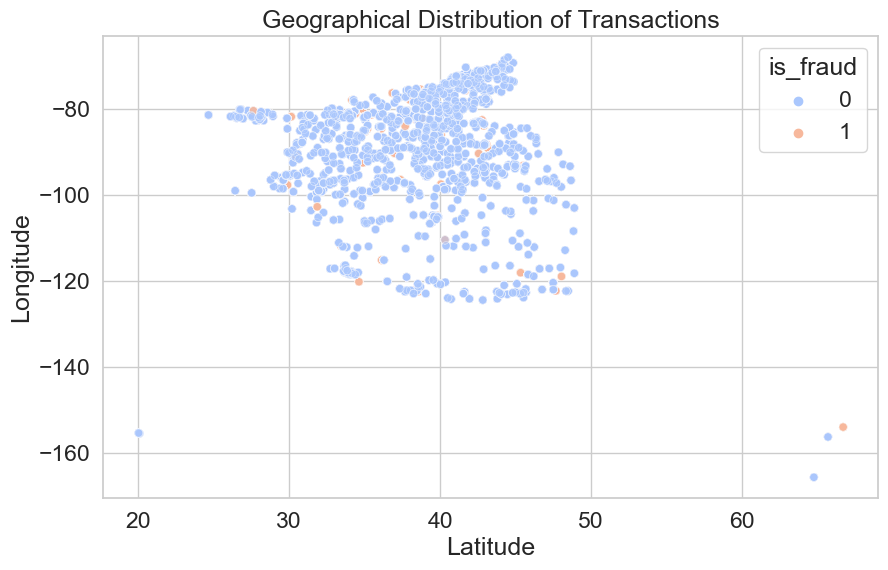

In [28]:
# Scatter plot of 'lat' and 'long'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='lat', y='long', hue='is_fraud', data=train_data, alpha=0.5, palette='coolwarm')
plt.title('Geographical Distribution of Transactions')
plt.xlabel('Latitude')
plt.ylabel('Longitude')
plt.show()


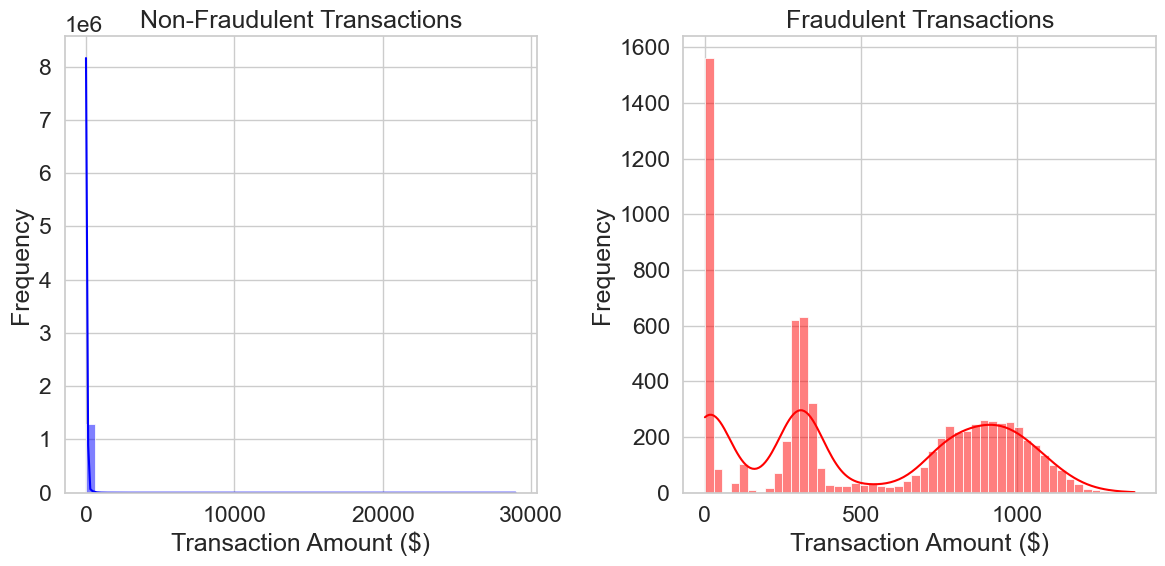

In [29]:
non_fraud_data = train_data[train_data['is_fraud'] == 0]
fraud_data = train_data[train_data['is_fraud'] == 1]
# Set up the figure
plt.figure(figsize=(12, 6))

# Distribution plot for non-fraudulent transactions
plt.subplot(1, 2, 1)
sns.histplot(non_fraud_data['amt'], bins=50, kde=True, color='blue')
plt.title('Non-Fraudulent Transactions')
plt.xlabel('Transaction Amount ($)')
plt.ylabel('Frequency')

# Distribution plot for fraudulent transactions
plt.subplot(1, 2, 2)
sns.histplot(fraud_data['amt'], bins=50, kde=True, color='red')
plt.title('Fraudulent Transactions')
plt.xlabel('Transaction Amount ($)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


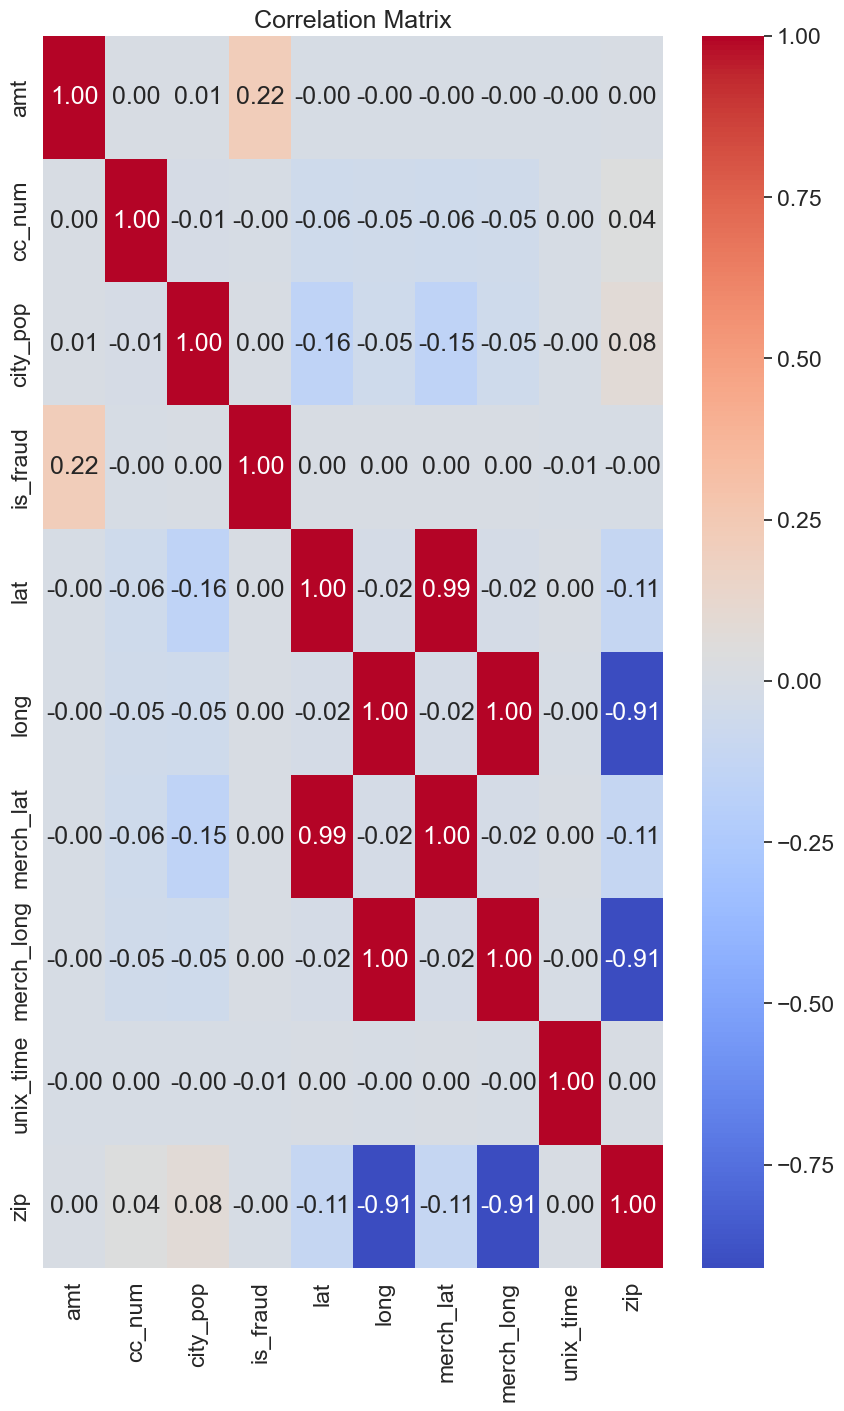

In [30]:
# Identify and exclude non-numeric columns
non_numeric_cols = train_data.select_dtypes(exclude=['float64', 'int64']).columns
numeric_cols = train_data.columns.difference(non_numeric_cols)

# Compute correlation matrix for numeric columns
corr_matrix = train_data[numeric_cols].corr()

# Plotting the correlation matrix
plt.figure(figsize=(10, 16))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm',fmt='.2f')
plt.title('Correlation Matrix')
plt.show()


# Transactions by Gender

F    709863
M    586812
Name: gender, dtype: int64
0    1289169
1       7506
Name: is_fraud, dtype: int64


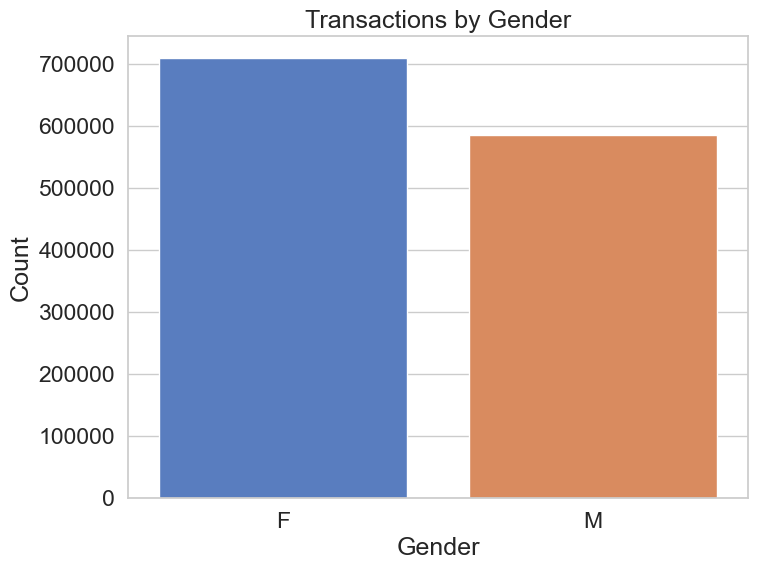

In [31]:
# Check data types and unique values
print(train_data['gender'].value_counts())
print(train_data['is_fraud'].value_counts())

# Plot directly without hue
plt.figure(figsize=(8, 6))
sns.countplot(x='gender', data=train_data)
plt.title('Transactions by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()


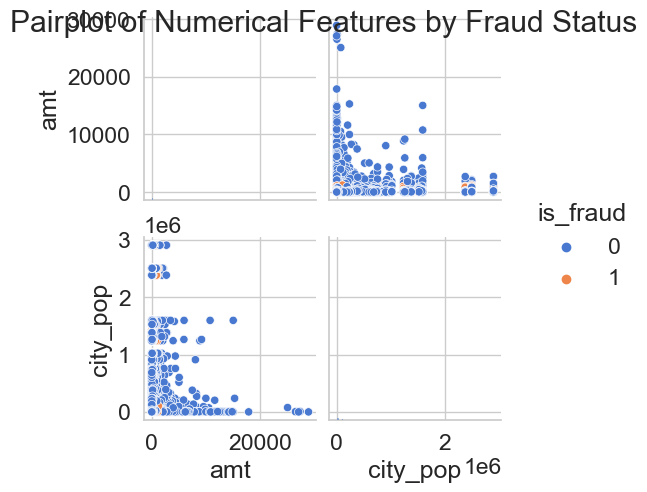

In [32]:
# Example with multiple features
sns.pairplot(train_data[['amt', 'city_pop', 'is_fraud']], hue='is_fraud', diag_kind='hist')
plt.suptitle('Pairplot of Numerical Features by Fraud Status')
plt.show()


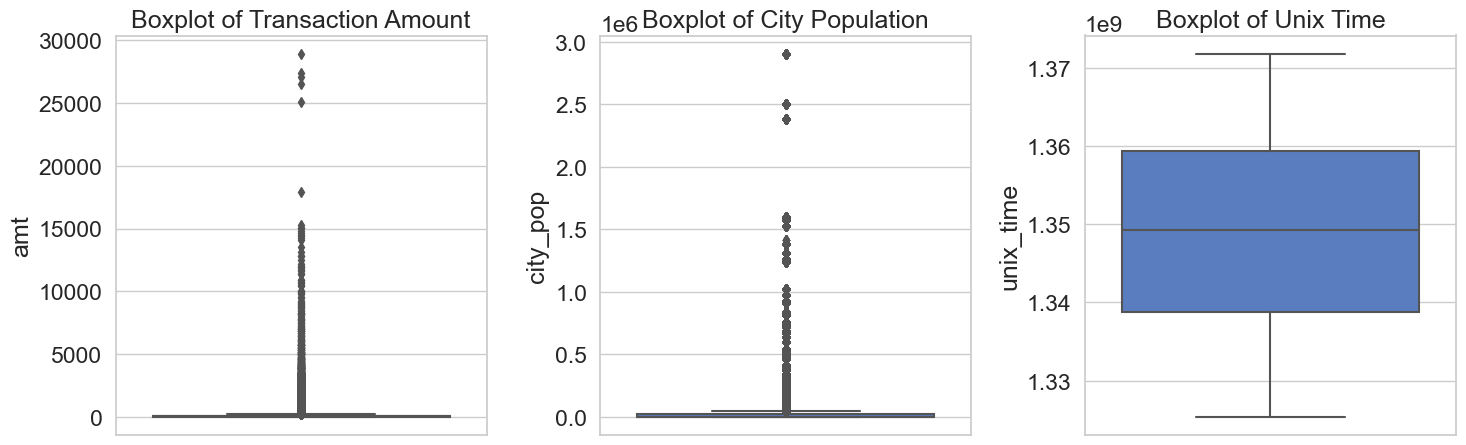

In [33]:
# Import necessary libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure size
plt.figure(figsize=(15, 5))

# Plotting boxplots for each feature
plt.subplot(1, 3, 1)
sns.boxplot(y='amt', data=train_data)
plt.title('Boxplot of Transaction Amount')

plt.subplot(1, 3, 2)
sns.boxplot(y='city_pop', data=train_data)
plt.title('Boxplot of City Population')

plt.subplot(1, 3, 3)
sns.boxplot(y='unix_time', data=train_data)
plt.title('Boxplot of Unix Time')

# Adjust layout and display
plt.tight_layout()
plt.show()


# Data preperation 

# Gender encoding 

In [41]:
from sklearn.preprocessing import LabelEncoder
# Initialize LabelEncoder
le_gender = LabelEncoder()

# Encode 'gender'
train_data['gender_encoded'] = le_gender.fit_transform(train_data['gender'])

# Drop the original 'gender' column if needed
# train_data.drop(['gender'], axis=1, inplace=True)
train_data.drop(['gender'], axis=1, inplace=True)

train_data['gender_encoded']


0          0
1          0
2          1
3          1
4          1
          ..
1296670    1
1296671    1
1296672    1
1296673    1
1296674    1
Name: gender_encoded, Length: 1296675, dtype: int32

# Merchant Encoding

In [42]:
# One-Hot Encoding for 'merchant'
merchant_dummies = pd.get_dummies(train_data['merchant'], prefix='merchant')

# Concatenate the one-hot encoded columns to the original DataFrame
train_data = pd.concat([train_data, merchant_dummies], axis=1)

# Drop the original 'merchant' column if needed
train_data.drop(['merchant'], axis=1, inplace=True)


In [43]:
train_data

,trans_date_trans_time,cc_num,category,amt,first,last,street,city,state,zip,...,"merchant_fraud_Yost, Schamberger and Windler",merchant_fraud_Yost-Rogahn,merchant_fraud_Zboncak LLC,merchant_fraud_Zboncak Ltd,"merchant_fraud_Zboncak, Rowe and Murazik",merchant_fraud_Zemlak Group,"merchant_fraud_Zemlak, Tillman and Cremin",merchant_fraud_Ziemann-Waters,"merchant_fraud_Zieme, Bode and Dooley",merchant_fraud_Zulauf LLC
0,2019-01-01 00:00:18,2703186189652095,misc_net,4.97,Jennifer,Banks,561 Perry Cove,Moravian Falls,NC,28654,...,0,0,0,0,0,0,0,0,0,0
1,2019-01-01 00:00:44,630423337322,grocery_pos,107.23,Stephanie,Gill,43039 Riley Greens Suite 393,Orient,WA,99160,...,0,0,0,0,0,0,0,0,0,0
2,2019-01-01 00:00:51,38859492057661,entertainment,220.11,Edward,Sanchez,594 White Dale Suite 530,Malad City,ID,83252,...,0,0,0,0,0,0,0,0,0,0
3,2019-01-01 00:01:16,3534093764340240,gas_transport,45.00,Jeremy,White,9443 Cynthia Court Apt. 038,Boulder,MT,59632,...,0,0,0,0,0,0,0,0,0,0
4,2019-01-01 00:03:06,375534208663984,misc_pos,41.96,Tyler,Garcia,408 Bradley Rest,Doe Hill,VA,24433,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,2020-06-21 12:12:08,30263540414123,entertainment,15.56,Erik,Patterson,162 Jessica Row Apt. 072,Hatch,UT,84735,...,0,0,0,0,0,0,0,0,0,0
1296671,2020-06-21 12:12:19,6011149206456997,food_dining,51.70,Jeffrey,White,8617 Holmes Terrace Suite 651,Tuscarora,MD,21790,...,0,0,0,0,0,0,0,0,0,0
1296672,2020-06-21 12:12:32,3514865930894695,food_dining,105.93,Christopher,Castaneda,1632 Cohen Drive Suite 639,High Rolls Mountain Park,NM,88325,...,0,0,0,0,0,0,0,0,0,0
1296673,2020-06-21 12:13:36,2720012583106919,food_dining,74.90,Joseph,Murray,42933 Ryan Underpass,Manderson,SD,57756,...,0,0,0,0,0,0,0,0,0,0


# Categorie Encoding

In [44]:
# One-Hot Encoding for 'category'
category_dummies = pd.get_dummies(train_data['category'], prefix='category')

# Concatenate the one-hot encoded columns to the original DataFrame
train_data = pd.concat([train_data, category_dummies], axis=1)

# Drop the original 'category' column if needed
train_data.drop(['category'], axis=1, inplace=True)


In [45]:
train_data

,trans_date_trans_time,cc_num,amt,first,last,street,city,state,zip,lat,...,category_grocery_pos,category_health_fitness,category_home,category_kids_pets,category_misc_net,category_misc_pos,category_personal_care,category_shopping_net,category_shopping_pos,category_travel
0,2019-01-01 00:00:18,2703186189652095,4.97,Jennifer,Banks,561 Perry Cove,Moravian Falls,NC,28654,36.0788,...,0,0,0,0,1,0,0,0,0,0
1,2019-01-01 00:00:44,630423337322,107.23,Stephanie,Gill,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,...,1,0,0,0,0,0,0,0,0,0
2,2019-01-01 00:00:51,38859492057661,220.11,Edward,Sanchez,594 White Dale Suite 530,Malad City,ID,83252,42.1808,...,0,0,0,0,0,0,0,0,0,0
3,2019-01-01 00:01:16,3534093764340240,45.00,Jeremy,White,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,...,0,0,0,0,0,0,0,0,0,0
4,2019-01-01 00:03:06,375534208663984,41.96,Tyler,Garcia,408 Bradley Rest,Doe Hill,VA,24433,38.4207,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,2020-06-21 12:12:08,30263540414123,15.56,Erik,Patterson,162 Jessica Row Apt. 072,Hatch,UT,84735,37.7175,...,0,0,0,0,0,0,0,0,0,0
1296671,2020-06-21 12:12:19,6011149206456997,51.70,Jeffrey,White,8617 Holmes Terrace Suite 651,Tuscarora,MD,21790,39.2667,...,0,0,0,0,0,0,0,0,0,0
1296672,2020-06-21 12:12:32,3514865930894695,105.93,Christopher,Castaneda,1632 Cohen Drive Suite 639,High Rolls Mountain Park,NM,88325,32.9396,...,0,0,0,0,0,0,0,0,0,0
1296673,2020-06-21 12:13:36,2720012583106919,74.90,Joseph,Murray,42933 Ryan Underpass,Manderson,SD,57756,43.3526,...,0,0,0,0,0,0,0,0,0,0


# State Encoding

In [47]:
# One-Hot Encoding for 'state'
state_dummies = pd.get_dummies(train_data['state'], prefix='state')

# Concatenate the one-hot encoded columns to the original DataFrame
train_data = pd.concat([train_data, state_dummies], axis=1)

# Drop the original 'state' column if needed
train_data.drop(['state'], axis=1, inplace=True)

In [48]:
train_data

,trans_date_trans_time,cc_num,amt,first,last,street,city,zip,lat,long,...,state_SD,state_TN,state_TX,state_UT,state_VA,state_VT,state_WA,state_WI,state_WV,state_WY
0,2019-01-01 00:00:18,2703186189652095,4.97,Jennifer,Banks,561 Perry Cove,Moravian Falls,28654,36.0788,-81.1781,...,0,0,0,0,0,0,0,0,0,0
1,2019-01-01 00:00:44,630423337322,107.23,Stephanie,Gill,43039 Riley Greens Suite 393,Orient,99160,48.8878,-118.2105,...,0,0,0,0,0,0,1,0,0,0
2,2019-01-01 00:00:51,38859492057661,220.11,Edward,Sanchez,594 White Dale Suite 530,Malad City,83252,42.1808,-112.2620,...,0,0,0,0,0,0,0,0,0,0
3,2019-01-01 00:01:16,3534093764340240,45.00,Jeremy,White,9443 Cynthia Court Apt. 038,Boulder,59632,46.2306,-112.1138,...,0,0,0,0,0,0,0,0,0,0
4,2019-01-01 00:03:06,375534208663984,41.96,Tyler,Garcia,408 Bradley Rest,Doe Hill,24433,38.4207,-79.4629,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,2020-06-21 12:12:08,30263540414123,15.56,Erik,Patterson,162 Jessica Row Apt. 072,Hatch,84735,37.7175,-112.4777,...,0,0,0,1,0,0,0,0,0,0
1296671,2020-06-21 12:12:19,6011149206456997,51.70,Jeffrey,White,8617 Holmes Terrace Suite 651,Tuscarora,21790,39.2667,-77.5101,...,0,0,0,0,0,0,0,0,0,0
1296672,2020-06-21 12:12:32,3514865930894695,105.93,Christopher,Castaneda,1632 Cohen Drive Suite 639,High Rolls Mountain Park,88325,32.9396,-105.8189,...,0,0,0,0,0,0,0,0,0,0
1296673,2020-06-21 12:13:36,2720012583106919,74.90,Joseph,Murray,42933 Ryan Underpass,Manderson,57756,43.3526,-102.5411,...,1,0,0,0,0,0,0,0,0,0


# Job Encoding

In [49]:
# Extract unique job titles
unique_jobs = train_data['job'].unique()

# Define the file path
file_path = 'unique_jobs.txt'

# Write unique job titles to a text file
with open(file_path, 'w') as file:
    for job in unique_jobs:
        file.write(job + '\n')

print(f"Unique job titles have been saved to {file_path}.")


Unique job titles have been saved to unique_jobs.txt.


In [50]:
job_to_industry = {
    # Education
    'Teacher': 'Education',
    'Professor': 'Education',
    'Lecturer': 'Education',
    'Instructor': 'Education',
    'Special educational needs teacher': 'Education',
    'Primary school teacher': 'Education',
    'Secondary school teacher': 'Education',
    'Early years teacher': 'Education',
    'Teacher, special educational needs': 'Education',
    'Teacher, English as a foreign language': 'Education',
    'Teacher, secondary school': 'Education',
    'Teacher, primary school': 'Education',
    'Teacher, adult education': 'Education',
    'Teacher, early years/pre': 'Education',
    'TEFL teacher': 'Education',
    'Teaching laboratory technician': 'Education',
    'Education administrator': 'Education',
    'Education officer, community': 'Education',
    'Education officer, museum': 'Education',
    'Education officer': 'Education',
    'Further education lecturer': 'Education',
    'Higher education careers adviser': 'Education',
    'Special educational needs teacher': 'Education',

    # Engineering
    'Engineer': 'Engineering',
    'Software Engineer': 'Engineering',
    'Mechanical Engineer': 'Engineering',
    'Electrical Engineer': 'Engineering',
    'Civil Engineer': 'Engineering',
    'Chemical Engineer': 'Engineering',
    'Biomedical Engineer': 'Engineering',
    'Systems Engineer': 'Engineering',
    'Aerospace Engineer': 'Engineering',
    'Environmental Engineer': 'Engineering',
    'Agricultural Engineer': 'Engineering',
    'Production Engineer': 'Engineering',
    'Mining Engineer': 'Engineering',
    'Marine Engineer': 'Engineering',
    'Geotechnical Engineer': 'Engineering',
    'Structural Engineer': 'Engineering',
    'Communications Engineer': 'Engineering',
    'Control and Instrumentation Engineer': 'Engineering',
    'Materials Engineer': 'Engineering',
    'Petroleum Engineer': 'Engineering',
    'Automotive Engineer': 'Engineering',
    'Drilling Engineer': 'Engineering',
    'Nuclear Engineer': 'Engineering',
    'Technical Sales Engineer': 'Engineering',
    'Network Engineer': 'Engineering',
    'Engineer, land': 'Engineering',
    'Engineer, electronics': 'Engineering',
    'Engineer, production': 'Engineering',
    'Engineer, technical sales': 'Engineering',
    'Engineer, manufacturing': 'Engineering',
    'Engineer, environmental': 'Engineering',
    'Engineer, petroleum': 'Engineering',
    'Engineer, software': 'Engineering',
    'Engineer, systems': 'Engineering',
    'Engineer, telecommunications': 'Engineering',
    'Engineer, automotive': 'Engineering',
    'Engineer, mining': 'Engineering',
    'Engineer, geotechnical': 'Engineering',
    'Engineer, civil (contracting)': 'Engineering',
    'Engineer, mechanical': 'Engineering',
    'Engineer, chemical': 'Engineering',
    'Engineer, control and instrumentation': 'Engineering',
    'Engineer, materials': 'Engineering',
    'Engineer, water': 'Engineering',
    'Engineer, structural': 'Engineering',
    'Engineer, naval architect': 'Engineering',
    'Engineer, site': 'Engineering',
    'Engineer, broadcasting (operations)': 'Engineering',
    'Engineer, electrical': 'Engineering',
    'Engineer, drilling': 'Engineering',
    'Engineer, electronics': 'Engineering',
    'Engineer, manufacturing': 'Engineering',
    'Engineer, civil (consulting)': 'Engineering',
    'Engineer, environmental': 'Engineering',

    # Healthcare
    'Doctor': 'Healthcare',
    'Nurse': 'Healthcare',
    'Therapist': 'Healthcare',
    'Pharmacist': 'Healthcare',
    'Psychologist': 'Healthcare',
    'Dentist': 'Healthcare',
    'Surgeon': 'Healthcare',
    'Optometrist': 'Healthcare',
    'Radiographer': 'Healthcare',
    'Paramedic': 'Healthcare',
    'Physiotherapist': 'Healthcare',
    'Dietitian': 'Healthcare',
    'Midwife': 'Healthcare',
    'Veterinary Surgeon': 'Healthcare',
    'Occupational Therapist': 'Healthcare',
    'Speech Therapist': 'Healthcare',
    'Clinical Scientist': 'Healthcare',
    'Podiatrist': 'Healthcare',
    'Psychiatrist': 'Healthcare',
    'Mental Health Nurse': 'Healthcare',
    'Medical Laboratory Technician': 'Healthcare',
    'Medical Technician': 'Healthcare',
    'Medical Secretary': 'Healthcare',
    'Clinical Psychologist': 'Healthcare',
    'Hospital Pharmacist': 'Healthcare',
    'Community Pharmacist': 'Healthcare',
    'Healthcare Scientist': 'Healthcare',
    'Cardiologist': 'Healthcare',
    'Healthcare Assistant': 'Healthcare',
    'Anesthetist': 'Healthcare',
    'Oncologist': 'Healthcare',
    'Psychotherapist': 'Healthcare',
    'Counsellor': 'Healthcare',
    'Public Health Specialist': 'Healthcare',
    'Biomedical Scientist': 'Healthcare',
    'Audiologist': 'Healthcare',
    'Chiropractor': 'Healthcare',
    'Genetic Counsellor': 'Healthcare',
    'Hearing Aid Dispenser': 'Healthcare',
    'Neonatal Nurse': 'Healthcare',
    'Orthoptist': 'Healthcare',
    'Phlebotomist': 'Healthcare',
    'Play Therapist': 'Healthcare',
    'Radiation Therapist': 'Healthcare',
    'Reflexologist': 'Healthcare',
    'Respiratory Therapist': 'Healthcare',
    'Sports Therapist': 'Healthcare',
    'Surgical Technologist': 'Healthcare',
    'Art Therapist': 'Healthcare',
    'Music Therapist': 'Healthcare',
    'Dance Therapist': 'Healthcare',
    'Dramatherapist': 'Healthcare',
    'Orthotist': 'Healthcare',
    'Prosthetist': 'Healthcare',
    'Pathologist': 'Healthcare',
    'Clinical Biochemist': 'Healthcare',
    'Neurosurgeon': 'Healthcare',
    'Orthopedic Surgeon': 'Healthcare',
    'Plastic Surgeon': 'Healthcare',
    'General Surgeon': 'Healthcare',
    'Urologist': 'Healthcare',
    'Physicist, medical': 'Healthcare',
    'Physiological scientist': 'Healthcare',
    'Osteopath': 'Healthcare',
    'Doctor, hospital': 'Healthcare',
    'Dietician': 'Healthcare',
    'Clinical scientist': 'Healthcare',
    'Clinical cytogeneticist': 'Healthcare',
    'Doctor, general practice': 'Healthcare',
    'Medical physicist': 'Healthcare',
    'Psychotherapist, child': 'Healthcare',
    'Therapist, art': 'Healthcare',
    'Therapist, music': 'Healthcare',
    'Therapist, horticultural': 'Healthcare',
    'Medical technical officer': 'Healthcare',
    'Scientist, clinical (histocompatibility and immunogenetics)': 'Healthcare',

    # Arts
    'Artist': 'Arts',
    'Designer': 'Arts',
    'Writer': 'Arts',
    'Photographer': 'Arts',
    'Producer': 'Arts',
    'Film Director': 'Arts',
    'Musician': 'Arts',
    'Actor': 'Arts',
    'Dancer': 'Arts',
    'Choreographer': 'Arts',
    'Graphic Designer': 'Arts',
    'Fashion Designer': 'Arts',
    'Interior Designer': 'Arts',
    'Architect': 'Arts',
    'Animator': 'Arts',
    'Illustrator': 'Arts',
    'Video Editor': 'Arts',
    'Editor, film/video': 'Arts',
    'Cinematographer': 'Arts',
    'Game Designer': 'Arts',
    'Set Designer': 'Arts',
    'Sound Engineer': 'Arts',
    'Make-up Artist': 'Arts',
    'Stage Manager': 'Arts',
    'Art Director': 'Arts',
    'Copywriter': 'Arts',
    'Creative Director': 'Arts',
    'Lighting Technician': 'Arts',
    'Scriptwriter': 'Arts',
    'Voice Actor': 'Arts',
    'Exhibition Designer': 'Arts',
    'Furniture Designer': 'Arts',
    'Jewellery Designer': 'Arts',
    'Printmaker': 'Arts',
    'Production Designer': 'Arts',
    'Sculptor': 'Arts',
    'Textile Designer': 'Arts',
    'Architectural Technologist': 'Arts',
    'Cartographer': 'Arts',
    'Conservator': 'Arts',
    'Curator': 'Arts',
    'Gallery Manager': 'Arts',
    'Gallery Curator': 'Arts',
    'Heritage Manager': 'Arts',
    'Museum Education Officer': 'Arts',
    'Museum/Gallery Exhibitions Officer': 'Arts',
    'Museum/Gallery Conservator': 'Arts',
    'Exhibitions Officer, Museum/Gallery': 'Arts',
    'Exhibition Designer': 'Arts',
    'Set Designer': 'Arts',
    'Theatre Director': 'Arts',
    'Costume Designer': 'Arts',
    'Prosthetics Artist': 'Arts',
    'Scenic Artist': 'Arts',
    'Prop Maker': 'Arts',
    'Sound Designer': 'Arts',
    'Theatre Manager': 'Arts',
    'Wardrobe Supervisor': 'Arts',
    'Art Gallery Manager': 'Arts',
    'Art Therapist': 'Arts',
    'Fine Artist': 'Arts',
    'Ceramics Designer': 'Arts',
    'Glass Blower/Designer': 'Arts',
    'Jewellery Designer': 'Arts',
    'Potter': 'Arts',
    'Special Effects Artist': 'Arts',
    'Animator': 'Arts',
    'Game Developer': 'Arts',
    'Graphic Artist': 'Arts',

    # Management
    'Manager': 'Management',
    'Director': 'Management',
    'Coordinator': 'Management',
    'Officer': 'Management',
    'CEO': 'Management',
    'CFO': 'Management',
    'COO': 'Management',
    'Chief Technology Officer': 'Management',
    'Chief Marketing Officer': 'Management',
    'Chief Strategy Officer': 'Management',
    'Chief Operating Officer': 'Management',
    'Chief Financial Officer': 'Management',
    'Chief Executive Officer': 'Management',
    'Chief of Staff': 'Management',
    'Chief Information Officer': 'Management',
    'Operations Manager': 'Management',
    'Project Manager': 'Management',
    'Program Manager': 'Management',
    'Product Manager': 'Management',
    'Sales Manager': 'Management',
    'Marketing Manager': 'Management',
    'Account Manager': 'Management',
    'HR Manager': 'Management',
    'Training and Development Manager': 'Management',
    'Business Development Manager': 'Management',
    'Risk Manager': 'Management',
    'Facilities Manager': 'Management',
    'Event Manager': 'Management',
    'Retail Manager': 'Management',
    'Supply Chain Manager': 'Management',
    'Logistics Manager': 'Management',
    'Quality Manager': 'Management',
    'Compliance Manager': 'Management',
    'Customer Service Manager': 'Management',
    'Community Manager': 'Management',
    'Brand Manager': 'Management',
    'Office Manager': 'Management',
    'Hotel Manager': 'Management',
    'Restaurant Manager': 'Management',
    'Bar Manager': 'Management',
    'Pub Manager': 'Management',
    'Nightclub Manager': 'Management',
    'Leisure Centre Manager': 'Management',
    'Fitness Centre Manager': 'Management',
    'Sports Centre Manager': 'Management',
    'Facilities Manager': 'Management',
    'Estate Manager': 'Management',
    'Warehouse Manager': 'Management',
    'Production Manager': 'Management',
    'Farm Manager': 'Management',
    'Theme Park Manager': 'Management',
    'Museum Manager': 'Management',
    'Library Manager': 'Management',
    'Heritage Manager': 'Management',
    'Conservation Manager': 'Management',
    'Volunteer Manager': 'Management',
    'Campaign Manager': 'Management',
    'PR Manager': 'Management',
    'Communications Manager': 'Management',
    'Digital Marketing Manager': 'Management',
    'Social Media Manager': 'Management',
    'E-commerce Manager': 'Management',
    'Product Manager': 'Management',
    'Category Manager': 'Management',
    'Brand Manager': 'Management',
    'Event Manager': 'Management',
    'Conference Manager': 'Management',
    'Exhibition Manager': 'Management',
    'Fundraising Manager': 'Management',
    'Operations Manager': 'Management',
    'Project Manager': 'Management',
    'Program Manager': 'Management',
    'Portfolio Manager': 'Management',
    'Asset Manager': 'Management',
    'Investment Manager': 'Management',
    'Property Manager': 'Management',
    'Facilities Manager': 'Management',
    'Office Manager': 'Management',
    'Administration Manager': 'Management',
    'PA to the CEO': 'Management',
    'Executive Assistant': 'Management',
    'Personal Assistant': 'Management',
    'Secretary': 'Management',
    'Office Administrator': 'Management',
    'Office Assistant': 'Management',
    'Receptionist': 'Management',

    # Science and Research
    'Scientist': 'Science and Research',
    'Researcher': 'Science and Research',
    'Analyst': 'Science and Research',
    'Biologist': 'Science and Research',
    'Chemist': 'Science and Research',
    'Physicist': 'Science and Research',
    'Geologist': 'Science and Research',
    'Ecologist': 'Science and Research',
    'Microbiologist': 'Science and Research',
    'Environmental Scientist': 'Science and Research',
    'Forensic Scientist': 'Science and Research',
    'Medical Scientist': 'Science and Research',
    'Clinical Scientist': 'Science and Research',
    'Pharmaceutical Scientist': 'Science and Research',
    'Food Scientist': 'Science and Research',
    'Materials Scientist': 'Science and Research',
    'Oceanographer': 'Science and Research',
    'Hydrologist': 'Science and Research',
    'Meteorologist': 'Science and Research',
    'Astronomer': 'Science and Research',
    'Astrophysicist': 'Science and Research',
    'Data Scientist': 'Science and Research',
    'Bioinformatician': 'Science and Research',
    'Geneticist': 'Science and Research',
    'Toxicologist': 'Science and Research',
    'Plant Scientist': 'Science and Research',
    'Animal Scientist': 'Science and Research',
    'Veterinary Scientist': 'Science and Research',
    'Soil Scientist': 'Science and Research',
    'Forestry Scientist': 'Science and Research',
    'Horticultural Scientist': 'Science and Research',
    'Agricultural Scientist': 'Science and Research',
    'Social Scientist': 'Science and Research',
    'Political Scientist': 'Science and Research',
    'Behavioral Scientist': 'Science and Research',
    'Cognitive Scientist': 'Science and Research',
    'Neuroscientist': 'Science and Research',
    'Anthropologist': 'Science and Research',
    'Archaeologist': 'Science and Research',
    'Linguist': 'Science and Research',
    'Psychologist': 'Science and Research',
    'Sociologist': 'Science and Research',
    'Economist': 'Science and Research',
    'Demographer': 'Science and Research',
    'Statistical Analyst': 'Science and Research',
    'Statistician': 'Science and Research',
    'Operations Research Analyst': 'Science and Research',
    'Policy Analyst': 'Science and Research',
    'Market Research Analyst': 'Science and Research',
    'Business Analyst': 'Science and Research',
    'Systems Analyst': 'Science and Research',
    'Research Scientist (medical)': 'Science and Research',
    'Research scientist (physical sciences)': 'Science and Research',
    'Research scientist (life sciences)': 'Science and Research',

    # Finance
    'Accountant': 'Finance',
    'Auditor': 'Finance',
    'Banker': 'Finance',
    'Trader': 'Finance',
    'Financial Analyst': 'Finance',
    'Investment Analyst': 'Finance',
    'Tax Advisor': 'Finance',
    'Financial Advisor': 'Finance',
    'Insurance Broker': 'Finance',
    'Insurance Underwriter': 'Finance',
    'Credit Analyst': 'Finance',
    'Risk Analyst': 'Finance',
    'Loan Officer': 'Finance',
    'Mortgage Advisor': 'Finance',
    'Treasurer': 'Finance',
    'Bookkeeper': 'Finance',
    'Payroll Specialist': 'Finance',
    'Billing Specialist': 'Finance',
    'Cost Accountant': 'Finance',
    'Budget Analyst': 'Finance',
    'Tax Specialist': 'Finance',
    'Forensic Accountant': 'Finance',
    'Financial Planner': 'Finance',
    'Investment Banker': 'Finance',
    'Portfolio Manager': 'Finance',
    'Hedge Fund Manager': 'Finance',
    'Asset Manager': 'Finance',
    'Wealth Manager': 'Finance',
    'Corporate Finance Analyst': 'Finance',
    'Finance Manager': 'Finance',
    'Chief Financial Officer': 'Finance',
    'Financial Controller': 'Finance',
    'Financial Director': 'Finance',
    'Accounting Manager': 'Finance',
    'Audit Manager': 'Finance',
    'Tax Manager': 'Finance',
    'Finance Assistant': 'Finance',
    'Accounting Assistant': 'Finance',
    'Bookkeeping Assistant': 'Finance',
    'Payroll Assistant': 'Finance',
    'Billing Assistant': 'Finance',
    'Cost Accounting Assistant': 'Finance',
    'Budget Assistant': 'Finance',
    'Tax Assistant': 'Finance',
    'Investment Assistant': 'Finance',
    'Portfolio Assistant': 'Finance',
    'Hedge Fund Assistant': 'Finance',
    'Asset Assistant': 'Finance',
    'Wealth Assistant': 'Finance',
    'Corporate Finance Assistant': 'Finance',

    # Technology
    'Technician': 'Technology',
    'Developer': 'Technology',
    'Programmer': 'Technology',
    'Consultant': 'Technology',
    'IT Consultant': 'Technology',
    'Web Developer': 'Technology',
    'Software Developer': 'Technology',
    'Data Analyst': 'Technology',
    'System Administrator': 'Technology',
    'Network Administrator': 'Technology',
    'Database Administrator': 'Technology',
    'Cyber Security Specialist': 'Technology',
    'IT Manager': 'Technology',
    'Chief Information Officer': 'Technology',
    'Chief Technology Officer': 'Technology',
    'Technical Support Specialist': 'Technology',
    'Help Desk Technician': 'Technology',
    'IT Support Specialist': 'Technology',
    'System Analyst': 'Technology',
    'Network Engineer': 'Technology',
    'Software Engineer': 'Technology',
    'Hardware Engineer': 'Technology',
    'Computer Scientist': 'Technology',
    'Information Security Analyst': 'Technology',
    'Cloud Architect': 'Technology',
    'DevOps Engineer': 'Technology',
    'Mobile Developer': 'Technology',
    'Game Developer': 'Technology',
    'UX/UI Designer': 'Technology',
    'Technical Writer': 'Technology',
    'IT Trainer': 'Technology',
    'Business Analyst': 'Technology',
    'Product Manager': 'Technology',
    'Project Manager': 'Technology',
    'Scrum Master': 'Technology',
        'Technical Lead': 'Technology',
    'Solution Architect': 'Technology',
    'Integration Specialist': 'Technology',
    'Application Developer': 'Technology',
    'Data Engineer': 'Technology',
    'Machine Learning Engineer': 'Technology',
    'AI Specialist': 'Technology',
    'Robotics Engineer': 'Technology',
    'Technical Support Engineer': 'Technology',
    'Information Systems Manager': 'Technology',
    'Telecommunications Engineer': 'Technology',
    'Network Architect': 'Technology',
    'Business Intelligence Analyst': 'Technology',
    'Data Scientist': 'Technology',
    'IT Director': 'Technology',
    'Systems Architect': 'Technology',
    'ERP Consultant': 'Technology',
    'Blockchain Developer': 'Technology',
    'IT Auditor': 'Technology',

    # Law
    'Lawyer': 'Law',
    'Attorney': 'Law',
    'Solicitor': 'Law',
    'Barrister': 'Law',
    'Legal Advisor': 'Law',
    'Legal Consultant': 'Law',
    'Paralegal': 'Law',
    'Legal Secretary': 'Law',
    'Corporate Lawyer': 'Law',
    'Criminal Lawyer': 'Law',
    'Family Lawyer': 'Law',
    'Tax Lawyer': 'Law',
    'Patent Attorney': 'Law',
    'Trademark Attorney': 'Law',
    'Notary': 'Law',
    'Litigation Lawyer': 'Law',
    'Mediation Specialist': 'Law',
    'Compliance Officer': 'Law',
    'Contract Specialist': 'Law',
    'General Counsel': 'Law',
    'Legal Executive': 'Law',
    'Public Defender': 'Law',
    'Prosecutor': 'Law',
    'Judge': 'Law',
    'Magistrate': 'Law',
    'Court Clerk': 'Law',
    'Legal Analyst': 'Law',
    'In-House Counsel': 'Law',
    'Regulatory Affairs Specialist': 'Law',

    # Public Service
    'Police Officer': 'Public Service',
    'Firefighter': 'Public Service',
    'Paramedic': 'Public Service',
    'EMT': 'Public Service',
    'Social Worker': 'Public Service',
    'Public Health Worker': 'Public Service',
    'Public Relations Specialist': 'Public Service',
    'Community Worker': 'Public Service',
    'Nonprofit Worker': 'Public Service',
    'Charity Worker': 'Public Service',
    'Environmental Health Officer': 'Public Service',
    'Housing Officer': 'Public Service',
    'Welfare Officer': 'Public Service',
    'Youth Worker': 'Public Service',
    'Probation Officer': 'Public Service',
    'Prison Officer': 'Public Service',
    'Court Officer': 'Public Service',
    'Immigration Officer': 'Public Service',
    'Customs Officer': 'Public Service',
    'Border Control Officer': 'Public Service',
    'Public Administrator': 'Public Service',
    'Government Officer': 'Public Service',
    'City Planner': 'Public Service',
    'Urban Planner': 'Public Service',
    'Building Inspector': 'Public Service',
    'Public Works Engineer': 'Public Service',
    'Transportation Planner': 'Public Service',
    'Public Policy Analyst': 'Public Service',
    'Legislative Assistant': 'Public Service',
    'Political Aide': 'Public Service',
    'Campaign Worker': 'Public Service',
    'Public Relations Officer': 'Public Service',
    'Public Affairs Consultant': 'Public Service',
    'Press Officer': 'Public Service',
    'Public Information Officer': 'Public Service',
    'Community Outreach Worker': 'Public Service',
    'Community Development Worker': 'Public Service',
    'Public Health Inspector': 'Public Service',
    'Public Health Nurse': 'Public Service',
    'Sanitation Worker': 'Public Service',
    'Public Transport Worker': 'Public Service',
    'Park Ranger': 'Public Service',
    'Forestry Worker': 'Public Service',
    'Wildlife Conservationist': 'Public Service',
    'Environmental Scientist': 'Public Service',
    'Environmental Consultant': 'Public Service',
    'Ecologist': 'Public Service',
    'Environmental Policy Analyst': 'Public Service',
    'Environmental Planner': 'Public Service',
    'Environmental Health Specialist': 'Public Service',
    'Emergency Management Specialist': 'Public Service',
    'Disaster Recovery Specialist': 'Public Service',

    # Culinary
    'Chef': 'Culinary',
    'Cook': 'Culinary',
    'Baker': 'Culinary',
    'Pastry Chef': 'Culinary',
    'Sous Chef': 'Culinary',
    'Line Cook': 'Culinary',
    'Prep Cook': 'Culinary',
    'Kitchen Assistant': 'Culinary',
    'Restaurant Manager': 'Culinary',
    'Catering Manager': 'Culinary',
    'Food and Beverage Manager': 'Culinary',
    'Barista': 'Culinary',
    'Bartender': 'Culinary',
    'Mixologist': 'Culinary',
    'Sommelier': 'Culinary',
    'Food Stylist': 'Culinary',
    'Food Critic': 'Culinary',
    'Food Scientist': 'Culinary',
    'Nutritionist': 'Culinary',
    'Dietitian': 'Culinary',
    'Culinary Instructor': 'Culinary',
    'Culinary Consultant': 'Culinary',
    'Culinary Writer': 'Culinary',
    'Food Blogger': 'Culinary',
    'Food Photographer': 'Culinary',
    'Culinary Arts Instructor': 'Culinary',
    'Culinary Director': 'Culinary',

    # Other
    'Administrator': 'Other',
    'Assistant': 'Other',
    'Clerk': 'Other',
    'Receptionist': 'Other',
    'Secretary': 'Other',
    'Cleaner': 'Other',
    'Janitor': 'Other',
    'Caretaker': 'Other',
    'Groundskeeper': 'Other',
    'Maintenance Worker': 'Other',
    'Security Guard': 'Other',
    'Driver': 'Other',
    'Delivery Driver': 'Other',
    'Truck Driver': 'Other',
    'Courier': 'Other',
    'Warehouse Worker': 'Other',
    'Forklift Operator': 'Other',
    'Stock Clerk': 'Other',
    'Inventory Clerk': 'Other',
    'Storekeeper': 'Other',
    'Sales Assistant': 'Other',
    'Sales Clerk': 'Other',
    'Retail Assistant': 'Other',
    'Shop Assistant': 'Other',
    'Customer Service Assistant': 'Other',
    'Customer Support Representative': 'Other',
    'Call Centre Operator': 'Other',
    'Telemarketer': 'Other',
    'Help Desk Assistant': 'Other',
    'Office Assistant': 'Other',
    'Administrative Assistant': 'Other',
    'Personal Assistant': 'Other',
    'Executive Assistant': 'Other',
    'PA to CEO': 'Other',
    'Secretary/Administrator': 'Other',
    'Office Administrator': 'Other',
    'Clerical Assistant': 'Other',
    'Receptionist/Administrator': 'Other',
    'General Clerk': 'Other',
    'Office Clerk': 'Other',
    'Data Entry Clerk': 'Other',
    'File Clerk': 'Other',
    'Accounts Clerk': 'Other',
    'Purchasing Clerk': 'Other',
    'Inventory Clerk': 'Other',
    'Warehouse Clerk': 'Other',
    'Shipping Clerk': 'Other',
    'Receiving Clerk': 'Other',
    'Logistics Clerk': 'Other',
    'Distribution Clerk': 'Other',
    'Production Clerk': 'Other',
    'Service Clerk': 'Other',
    'Sales Clerk': 'Other',
    'Retail Clerk': 'Other',
    'Customer Service Clerk': 'Other',
    'Customer Support Clerk': 'Other',
    'Help Desk Clerk': 'Other',
    'Call Centre Clerk': 'Other',
    'Telemarketing Clerk': 'Other',
    'Administrative Clerk': 'Other',
    'Office Clerk/Assistant': 'Other',
    'Administrative Assistant/Clerk': 'Other',
    'Personal Assistant/Secretary': 'Other',
    'Executive Assistant/PA': 'Other',
    'PA/Secretary': 'Other',
    'Office Administrator/Clerk': 'Other',
    'Clerical Assistant/Clerk': 'Other',
    'Receptionist/Clerk': 'Other',
    'General Clerk/Assistant': 'Other',
    'Data Entry Clerk/Assistant': 'Other',
    'File Clerk/Assistant': 'Other',
    'Accounts Clerk/Assistant': 'Other',
    'Purchasing Clerk/Assistant': 'Other',
    'Inventory Clerk/Assistant': 'Other',
    'Warehouse Clerk/Assistant': 'Other',
    'Shipping Clerk/Assistant': 'Other',
    'Receiving Clerk/Assistant': 'Other',
    'Logistics Clerk/Assistant': 'Other',
    'Distribution Clerk/Assistant': 'Other',
    'Production Clerk/Assistant': 'Other',
    'Service Clerk/Assistant': 'Other',
    'Sales Clerk/Assistant': 'Other',
    'Retail Clerk/Assistant': 'Other',
    'Customer Service Clerk/Assistant': 'Other',
    'Customer Support Clerk/Assistant': 'Other',
    'Help Desk Clerk/Assistant': 'Other',
    'Call Centre Clerk/Assistant': 'Other',
    'Telemarketing Clerk/Assistant': 'Other'
}

   


In [51]:
train_data['industry'] = train_data['job'].map(job_to_industry)

In [52]:
train_data['industry'].fillna('Other', inplace=True)

In [53]:
industry_dummies = pd.get_dummies(train_data['industry'], prefix='industry')

In [54]:
train_data = pd.concat([train_data, industry_dummies], axis=1)

# Drop the original 'job' and 'industry' columns
train_data.drop(['job', 'industry'], axis=1, inplace=True)

In [55]:
train_data

,trans_date_trans_time,cc_num,amt,first,last,street,city,zip,lat,long,...,industry_Education,industry_Engineering,industry_Finance,industry_Healthcare,industry_Law,industry_Management,industry_Other,industry_Public Service,industry_Science and Research,industry_Technology
0,2019-01-01 00:00:18,2703186189652095,4.97,Jennifer,Banks,561 Perry Cove,Moravian Falls,28654,36.0788,-81.1781,...,0,0,0,0,0,0,1,0,0,0
1,2019-01-01 00:00:44,630423337322,107.23,Stephanie,Gill,43039 Riley Greens Suite 393,Orient,99160,48.8878,-118.2105,...,1,0,0,0,0,0,0,0,0,0
2,2019-01-01 00:00:51,38859492057661,220.11,Edward,Sanchez,594 White Dale Suite 530,Malad City,83252,42.1808,-112.2620,...,0,0,0,0,0,0,1,0,0,0
3,2019-01-01 00:01:16,3534093764340240,45.00,Jeremy,White,9443 Cynthia Court Apt. 038,Boulder,59632,46.2306,-112.1138,...,0,0,0,0,0,0,1,0,0,0
4,2019-01-01 00:03:06,375534208663984,41.96,Tyler,Garcia,408 Bradley Rest,Doe Hill,24433,38.4207,-79.4629,...,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,2020-06-21 12:12:08,30263540414123,15.56,Erik,Patterson,162 Jessica Row Apt. 072,Hatch,84735,37.7175,-112.4777,...,0,0,0,0,0,0,1,0,0,0
1296671,2020-06-21 12:12:19,6011149206456997,51.70,Jeffrey,White,8617 Holmes Terrace Suite 651,Tuscarora,21790,39.2667,-77.5101,...,0,0,0,0,0,0,1,0,0,0
1296672,2020-06-21 12:12:32,3514865930894695,105.93,Christopher,Castaneda,1632 Cohen Drive Suite 639,High Rolls Mountain Park,88325,32.9396,-105.8189,...,0,0,0,0,0,0,1,0,0,0
1296673,2020-06-21 12:13:36,2720012583106919,74.90,Joseph,Murray,42933 Ryan Underpass,Manderson,57756,43.3526,-102.5411,...,0,0,0,0,0,0,1,0,0,0


# feature extraction

# Time
Time-Based Features:

trans_hour: Hour of the transaction. This can help identify patterns related to the time of day when fraudulent transactions are more likely to occur.

trans_day: Day of the transaction.Identifies specific days when transactions are more frequent or fraudulent.

trans_month: Month of the transaction.Useful for seasonal analysis.

trans_year: Year of the transaction.Helps in analyzing trends over the years.

trans_day_of_week: Day of the week of the transaction.Useful for identifying patterns related to weekdays vs. weekends.

is_weekend: Whether the transaction occurred on a weekend.Binary feature indicating if the transaction happened on a weekend, which could be significant for fraud detection.


In [34]:
# Convert transaction date to datetime
train_data['trans_date_trans_time'] = pd.to_datetime(train_data['trans_date_trans_time'])

# Extracting time-based features
train_data['trans_hour'] = train_data['trans_date_trans_time'].dt.hour
train_data['trans_day'] = train_data['trans_date_trans_time'].dt.day
train_data['trans_month'] = train_data['trans_date_trans_time'].dt.month
train_data['trans_year'] = train_data['trans_date_trans_time'].dt.year
train_data['trans_day_of_week'] = train_data['trans_date_trans_time'].dt.dayofweek
train_data['is_weekend'] = train_data['trans_day_of_week'].apply(lambda x: 1 if x >= 5 else 0)


# Log Transformation:

log_amt: Log-transformed transaction amount to handle skewness.The log transformation helps in normalizing the skewed distribution of transaction amounts, making it easier for the model to learn.


In [35]:
train_data['log_amt'] = np.log1p(train_data['amt'])

# Calculate distance between merchant and user location
Geographic Feature:

distance: Distance between the merchant location and the user's location.The distance between the user and the merchant can be a crucial feature. Unusually large distances might indicate potential fraud.

In [36]:

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Radius of the Earth in kilometers
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) * np.sin(dlon / 2) + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon / 2) * np.sin(dlon / 2)
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    distance = R * c
    return distance

In [37]:
train_data['distance'] = train_data.apply(lambda row: haversine(row['lat'], row['long'], row['merch_lat'], row['merch_long']), axis=1)

# Count the number of transactions per user and per merchant
Frequency Features:

user_trans_count: Number of transactions per user.High transaction counts for a single user in a short time may indicate fraud.

merchant_trans_count: Number of transactions per merchant.Helps in identifying merchants with abnormally high transaction volumes, which could be suspicious.

In [38]:
train_data['user_trans_count'] = train_data.groupby('cc_num')['trans_num'].transform('count')
train_data['merchant_trans_count'] = train_data.groupby('merchant')['trans_num'].transform('count')

# Convert date of birth to datetime and calculate age
User Demographics:

age: User's age calculated from their date of birth.The user's age can be a significant factor in fraud detection. Certain age groups might be more prone to fraud or less likely to conduct high-value transactions.

In [39]:
train_data['dob'] = pd.to_datetime(train_data['dob'])
train_data['age'] = train_data['trans_date_trans_time'].dt.year - train_data['dob'].dt.year

In [40]:
train_data

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,trans_day,trans_month,trans_year,trans_day_of_week,is_weekend,log_amt,distance,user_trans_count,merchant_trans_count,age
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,1,1,2019,1,0,1.786747,82.750173,2028,1267,31
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,1,1,2019,1,0,4.684259,9.148239,3030,2503,41
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,1,1,2019,1,0,5.398660,36.968249,503,1895,57
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,1,1,2019,1,0,3.828641,NaN,493,2613,52
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,1,1,2019,1,0,3.760269,88.468076,2017,1592,33
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,2020-06-21 12:12:08,30263540414123,fraud_Reichel Inc,entertainment,15.56,Erik,Patterson,M,162 Jessica Row Apt. 072,Hatch,...,21,6,2020,6,1,2.806990,NaN,1513,1907,59
1296671,2020-06-21 12:12:19,6011149206456997,fraud_Abernathy and Sons,food_dining,51.70,Jeffrey,White,M,8617 Holmes Terrace Suite 651,Tuscarora,...,21,6,2020,6,1,3.964615,85.534477,531,1751,41
1296672,2020-06-21 12:12:32,3514865930894695,fraud_Stiedemann Ltd,food_dining,105.93,Christopher,Castaneda,M,1632 Cohen Drive Suite 639,High Rolls Mountain Park,...,21,6,2020,6,1,4.672174,99.406027,2070,1853,53
1296673,2020-06-21 12:13:36,2720012583106919,"fraud_Reinger, Weissnat and Strosin",food_dining,74.90,Joseph,Murray,M,42933 Ryan Underpass,Manderson,...,21,6,2020,6,1,4.329417,90.069191,2024,1910,40


# Time since last transaction


In [56]:
train_data['time_since_last_trans'] = train_data.sort_values(by=['cc_num', 'trans_date_trans_time']).groupby('cc_num')['trans_date_trans_time'].diff().dt.total_seconds()

# Average transaction amount per user


In [57]:
train_data['avg_trans_amt'] = train_data.groupby('cc_num')['amt'].transform('mean')

# Standard deviation of transaction amounts per user

In [58]:
train_data['std_trans_amt'] = train_data.groupby('cc_num')['amt'].transform('std')

# Rolling sum of transaction amounts (last 7 days)

In [59]:
def calculate_rolling_sum(df, window, groupby_col, target_col):
    df = df.sort_values(by=['cc_num', 'trans_date_trans_time'])
    rolling_sum = df.groupby(groupby_col).rolling(window=window, on='trans_date_trans_time')[target_col].sum().reset_index(level=0, drop=True)
    return rolling_sum


In [121]:
def calculate_rolling_sum(df, days, groupby_col, target_col):
    df = df.sort_values(by=['cc_num', 'trans_date_trans_time'])
    rolling_sums = []
    for cc_num, group in df.groupby(groupby_col):
        group = group.set_index('trans_date_trans_time')
        rolling_sum = group[target_col].rolling(window=f'{days}D').sum()
        rolling_sums.append(rolling_sum)
    return pd.concat(rolling_sums).sort_index()

# Calculate rolling sums for 3, 6, 9, and 12 months
train_data['rolling_sum_3m'] = calculate_rolling_sum(train_data, 90, 'cc_num', 'amt')
train_data['rolling_sum_6m'] = calculate_rolling_sum(train_data, 180, 'cc_num', 'amt')
train_data['rolling_sum_9m'] = calculate_rolling_sum(train_data, 270, 'cc_num', 'amt')
train_data['rolling_sum_12m'] = calculate_rolling_sum(train_data, 365, 'cc_num', 'amt')

ValueError: cannot reindex on an axis with duplicate labels

# Feature selection 

# Correlation Analysis

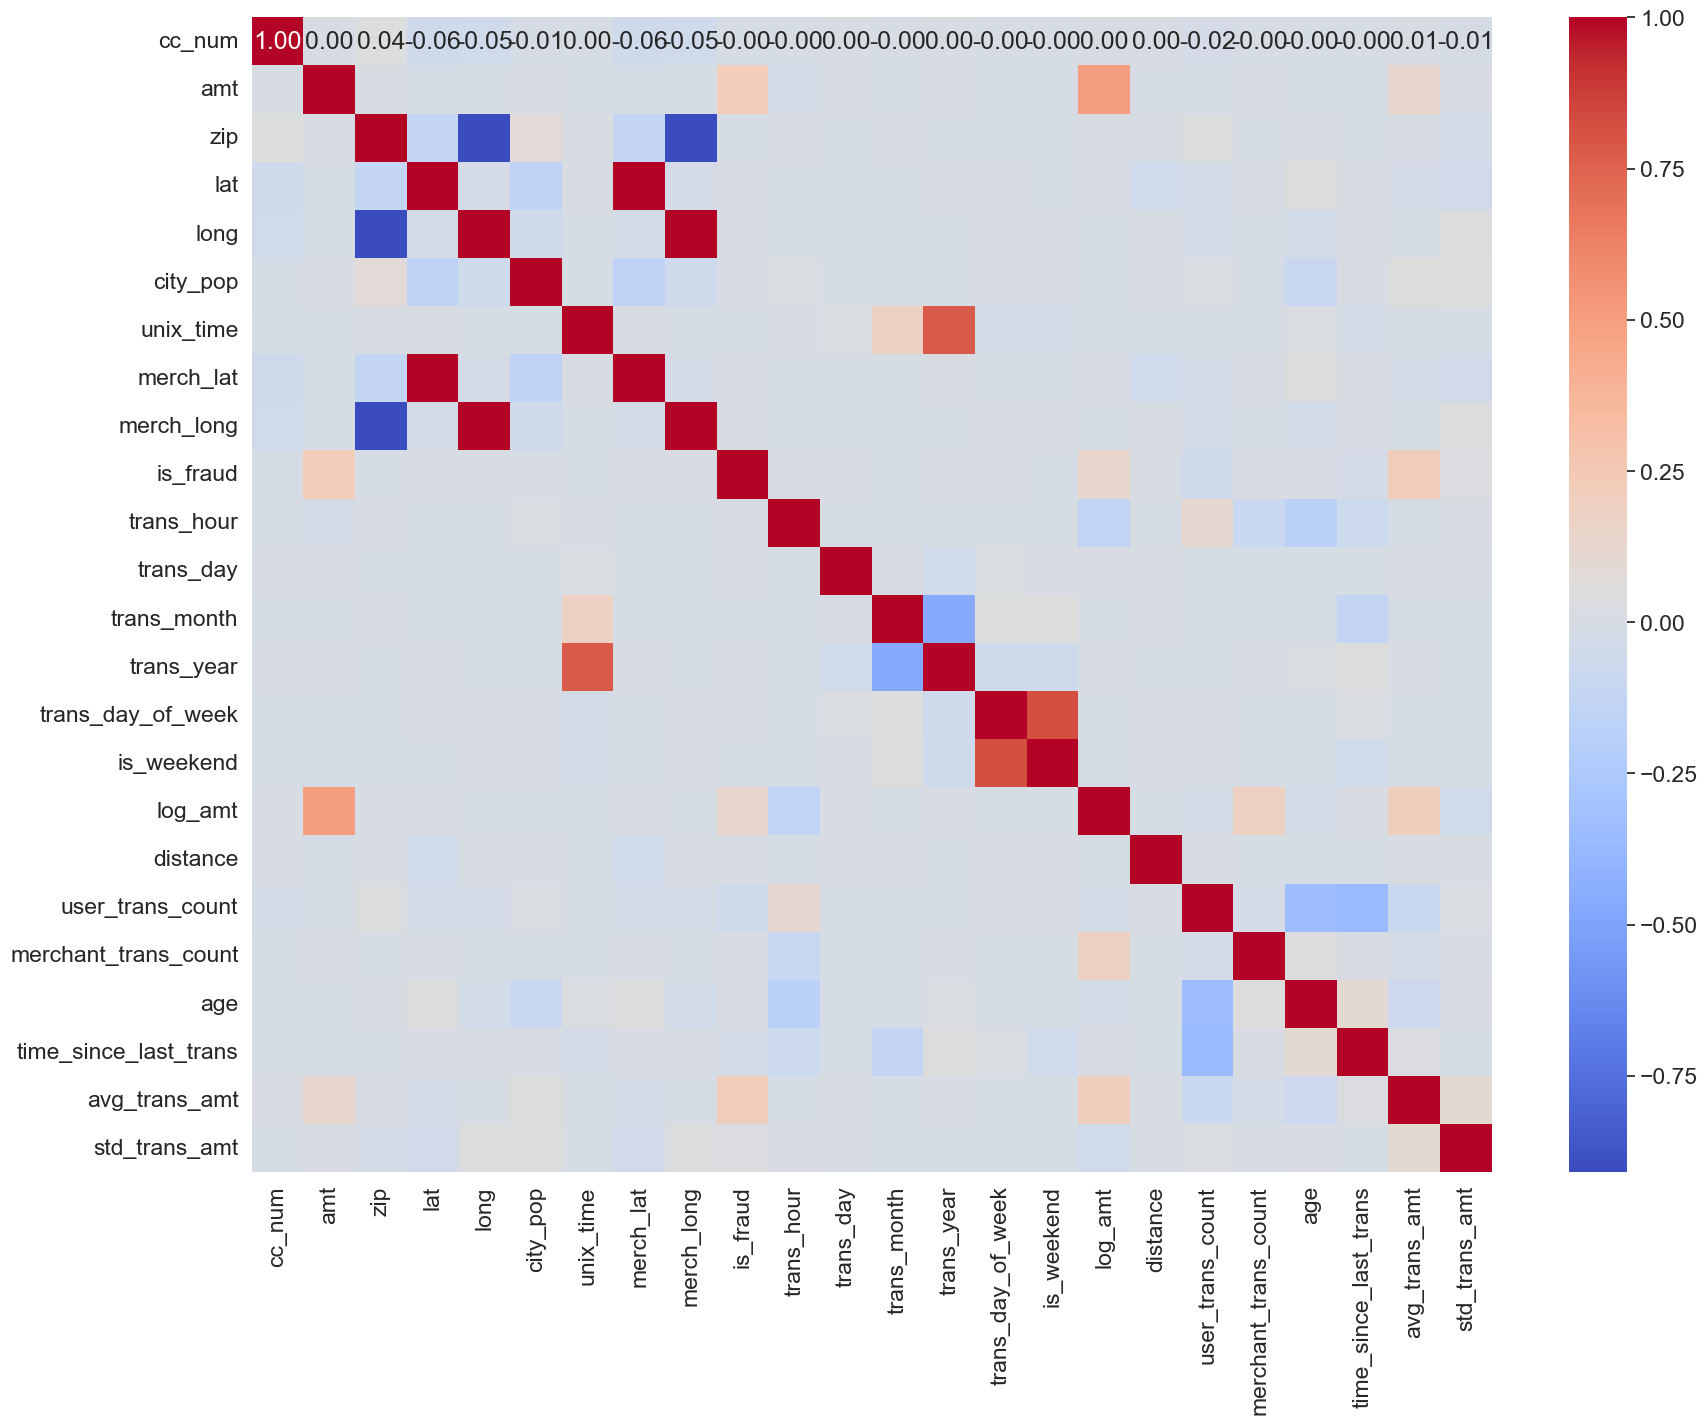

Highly correlated features: [('zip', 'long'), ('zip', 'merch_long'), ('lat', 'merch_lat'), ('long', 'merch_long'), ('trans_day_of_week', 'is_weekend')]


In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numeric columns
numeric_data = train_data.select_dtypes(include=[np.number])

# Calculate correlation matrix
corr_matrix = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(20, 15))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

# Identify highly correlated features (threshold > 0.8)
high_corr_var = np.where(abs(corr_matrix) > 0.8)
high_corr_var = [(corr_matrix.index[x], corr_matrix.columns[y]) for x, y in zip(*high_corr_var) if x != y and x < y]

print("Highly correlated features:", high_corr_var)


# Remove Highly Correlated Features

In [31]:
# Threshold for identifying highly correlated features
threshold = 0.8

# Create a correlation matrix
corr_matrix = numeric_data.corr()

# Find pairs of highly correlated features
high_corr_pairs = [(i, j) for i in corr_matrix.columns for j in corr_matrix.columns if i != j and abs(corr_matrix.loc[i, j]) > threshold]

# Create a set to hold features to be removed
features_to_remove = set()

# Loop through the pairs and add one feature from each pair to the set
for i, j in high_corr_pairs:
    if i not in features_to_remove and j not in features_to_remove:
        features_to_remove.add(j)  # Arbitrarily remove the second feature

print("Features to remove due to high correlation:", features_to_remove)

# Drop the features from the original DataFrame
train_data_reduced = train_data.drop(columns=features_to_remove)

# Display the first few rows of the reduced DataFrame
print(train_data_reduced.head())


Features to remove due to high correlation: {'merch_lat', 'merch_long', 'is_weekend', 'long'}
  trans_date_trans_time            cc_num                            merchant  \
0   2019-01-01 00:00:18  2703186189652095          fraud_Rippin, Kub and Mann   
1   2019-01-01 00:00:44      630423337322     fraud_Heller, Gutmann and Zieme   
2   2019-01-01 00:00:51    38859492057661                fraud_Lind-Buckridge   
3   2019-01-01 00:01:16  3534093764340240  fraud_Kutch, Hermiston and Farrell   
4   2019-01-01 00:03:06   375534208663984                 fraud_Keeling-Crist   

        category     amt      first     last gender  \
0       misc_net    4.97   Jennifer    Banks      F   
1    grocery_pos  107.23  Stephanie     Gill      F   
2  entertainment  220.11     Edward  Sanchez      M   
3  gas_transport   45.00     Jeremy    White      M   
4       misc_pos   41.96      Tyler   Garcia      M   

                         street            city  ... trans_year  \
0                561 

In [30]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

# Assuming 'is_fraud' is the target variable and it's already numeric
# If not, convert 'is_fraud' to numeric
if train_data['is_fraud'].dtype == 'object':
    le = LabelEncoder()
    train_data['is_fraud'] = le.fit_transform(train_data['is_fraud'])

X = numeric_data.drop('is_fraud', axis=1)
y = train_data['is_fraud']

# Handle missing values
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# Apply SelectKBest with mutual information
selector = SelectKBest(score_func=mutual_info_classif, k=10)
selector.fit(X_imputed, y)

# Get columns to keep
cols = selector.get_support(indices=True)
selected_features = X.columns[cols]
print("Selected features:", selected_features)


Selected features: Index(['amt', 'unix_time', 'trans_hour', 'trans_day', 'trans_month',
       'trans_year', 'trans_day_of_week', 'is_weekend', 'log_amt', 'distance'],
      dtype='object')


In [33]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 47 columns):
 #   Column                         Non-Null Count    Dtype         
---  ------                         --------------    -----         
 0   trans_date_trans_time          1296675 non-null  datetime64[ns]
 1   cc_num                         1296675 non-null  int64         
 2   merchant                       1296675 non-null  object        
 3   category                       1296675 non-null  object        
 4   amt                            1296675 non-null  float64       
 5   first                          1296675 non-null  object        
 6   last                           1296675 non-null  object        
 7   gender                         1296675 non-null  object        
 8   street                         1296675 non-null  object        
 9   city                           1296675 non-null  object        
 10  state                          1296675 non-null  objec

In [34]:
columns_to_drop = ['trans_date_trans_time', 'cc_num', 'first', 'last', 'street', 'city']
train_data_reduced = train_data_reduced.drop(columns=columns_to_drop)